In [683]:
import sys
sys.path.append('../scripts')  # Adjust path as needed
from module import (
    count_usage_cases,
    create_degree_lists,
    count_cluster_wise,
    pre_vec,
    nordept,
    deptwisecount,
    normalized_dept_cluster,
    create_vector,
    create_vector2,
    create_vector3,
    clear_vec,
    culster_wise_val,
    create_con_table,
    chi_square_test,
    residuals_cal,
    create_group,
    normality_test,
    agostino_pearson_test,
    kruskal_wallis_test
)
from plots import ( grouped_bar_graph_horizontal_color, stacked_bar_graph, grouped_bar_graph_horizontal_color_white, boxplot,
    kde_plot,
    heatmap_plot
)

In [684]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
import matplotlib.patches as mpatches  # For patterns

In [713]:
from scipy import stats
from statsmodels.miscmodels.ordinal_model import OrderedModel

In [686]:
file_path = '/Users/jesanahammed/Desktop/dataset/survey25.csv'
df_25 = pd.read_csv(file_path, encoding='latin1')

In [687]:
with open(file_path, 'r', encoding='latin1') as f:
    for i in range(5):
        print(f"Line {i+1}:")
        print(repr(f.readline()[:500]))

Line 1:
'Response ID,Response Status,IP Address,Timestamp (mm/dd/yyyy),Duplicate,Time Taken to Complete (Seconds),Seq. Number,External Reference,Custom Variable 1,Custom Variable 2,Custom Variable 3,Custom Variable 4,Custom Variable 5,Respondent Email,Email List,Country Code,Region,Research on Generative AI at Mines,"Thanks for clicking into this research study!Since 2023, researchers at the Colorado School of Mines have conducted annual surveys of students and faculty about Generative Artificial Intelli'
Line 2:
',,,,,,,,,,,,,,,,,,,,,,,"LLM-powered chatbots (e.g. ChatGPT, Gemini, Claude, Llama, etc.)",HiTA\xa0(A custom LLM-powered tool available in certain Mines classes.),"LLM-powered\xa0features\xa0in other applications (e.g., Copilot, Cursor, or other IDE-integrated LLMs,\xa0 Grammarly, Repl.it, and \x93auto-completion\x94 or \x93text suggestion\x94 features in email, docs, search engines, Overleaf, etc.)","Image generators\xa0(e.g. DALL-E, Midjourney, etc.)","Other\xa0media generat

In [20]:
# file_path = '/Users/jesanahammed/Desktop/dataset/Fall26/survey26.csv'
# clean_path = '/Users/jesanahammed/Desktop/dataset/Fall26/survey26_clean.csv'

# with open(file_path, 'r', encoding='latin1', newline='') as infile:
#     lines = infile.readlines()

# with open(clean_path, 'w', encoding='latin1', newline='') as outfile:
#     outfile.writelines(lines[3:])

# print("Cleaned CSV saved!")

In [28]:
# file_path = '/Users/jesanahammed/Desktop/dataset/Fall26/survey26_clean.csv'
# df_26 = pd.read_csv(file_path, encoding='latin1')

In [688]:
with open(file_path, 'r', encoding='latin1') as f:
    for line_number, line in enumerate(f, start=1):
        if line_number == 691:
            print(repr(line))
            break

'191086818,Completed,2600:100e:b080:2904:9878:6aa4:77b8:54c3,10/06/2025 14:02,FALSE,415,1,,,,,,,,,US,CO,,,1,1,1,,3,3,2,1,1,1,1,6,6,6,3,2,,1,1,1,1,1,1,1,,,,,,,1,1,1,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,7,3,6,6,5,7,6,,,,,,,,,,,6,4,1,,,,,,1,,,1,,,,,,,1,,,,1,,,,,,,,,,,,,,,,,,,,,1,,,,,,,1,,,,1,,,,,5,75,,12,,19,,,,,,,1,1,,1,,,,1,,,1,,2,2,6,\n'


In [689]:
file_path = '/Users/jesanahammed/Desktop/dataset/Fall26/survey26_clean.csv'
repaired_path = '/Users/jesanahammed/Desktop/dataset/Fall26/survey26_repaired.csv'

# Read the CSV as raw text
with open(file_path, 'r', encoding='latin1', newline='') as f:
    content = f.read()

# Fix the unescaped quotation marks in this specific response
old_text = 'I feel like I am doing "okay" at keeping'
new_text = 'I feel like I am doing ""okay"" at keeping'

print("Occurrences found:", content.count(old_text))

content = content.replace(old_text, new_text)

content = content.replace(
    'my "proposed" project',
    'my ""proposed"" project'
)

# Save the repaired CSV as a separate file
with open(repaired_path, 'w', encoding='latin1', newline='') as f:
    f.write(content)

Occurrences found: 1


In [690]:
df_26 = pd.read_csv(repaired_path, encoding='latin1')
print("Dataset shape:", df_26.shape)
print("Number of columns:", len(df_26.columns))
df_26.head()

Dataset shape: (1214, 208)
Number of columns: 208


,Response ID,Response Status,IP Address,Timestamp (mm/dd/yyyy),Duplicate,Time Taken to Complete (Seconds),Seq. Number,External Reference,Custom Variable 1,Custom Variable 2,...,Unnamed: 198,Unnamed: 199,Unnamed: 200,Unnamed: 201,[Q57-C5-C69] What is your gender?,Unnamed: 203,[Q19] Are you a first-generation college student meaning that your parents or guardians did not complete a bachelor's degree from a four-year college or university?,[Q20] This ladder is a representation of socioeconomic status.At the top of the ladder are the people who are the best off those who have the most money most education and best jobs. At the bottom are the people who are the worst off those who have the least money least education worst jobs or no job. Where do you think your family stands on the ladder?,[Q38] You may now submit this survey fully anonymouslyÂ orÂ you can provide your Mines email.Providing your Mines email will help the the scientific community to understand impactful questions about how students reported GenAI use correlates with actual academic performance. InÂ Fall25 over 450 students opted in which is incredible for the scientific questions we hope to answer--thank you so much. If you were one of them please do share again this year! We can analyze how your responses changed in the last year and improve the granularity of our analysis.Â But this is fullyÂ optionalÂ and we genuinely appreciate your participation either way. If you wish to authorize the release of FERPA-protected records please provide your Mines email. If not click the Done button below to submit your response anonymously.AUTHORIZATION FOR RELEASE OF EDUCATION RECORDS FOR RESEARCH:Some of the individual student data the research team will access is protected as education records under the Family Educational Rights and Privacy Act (FERPA). FERPA is a federal law that gives students various rights with respect to their education records. Under FERPA you have the right to inspect and review your education records the right to request amendment of records you believe are inaccurate or misleading and the right to prevent disclosure of information from your education records without your prior consent subject to some specific exceptions.Â I hereby authorize Colorado School of Mines to disclose records of my transcript and grades (including overall GPA)Â upon request to exactly one trained PhD researcher in the research lab of Prof. C. Estelle Smith. This information will never be shared beyond that one PhD researcher and will have no academic repercussions. Even if you are a student actively or previously enrolled in Prof. Smiths or Fierros course(s) they willÂ notÂ view your survey response. Your FERPA-protected data may be released to this PhD researcher only after grades have been submitted at the end of the Fall 2026 semester.Â Provide your Mines email if you authorize the future release of your transcript and GPA:,Unnamed: 207
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Middle Eastern,White,Prefer not to answer,Something Else,NaN,Dynamic Comment,NaN,NaN,NaN,NaN
1,236420301.0,Completed,138.67.168.159,10/05/2026 07:50:17,0.0,261.0,1.0,NaN,NaN,NaN,...,0,1,0,0,2.0,NaN,NaN,NaN,NaN,NaN
2,236420308.0,Started,138.67.127.163,10/05/2026 07:50:20,0.0,1030.0,1.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,236420312.0,Completed,138.67.127.134,10/05/2026 07:50:22,0.0,658.0,1.0,NaN,NaN,NaN,...,0,1,0,0,1.0,NaN,NaN,NaN,NaN,NaN
4,236420337.0,Completed,138.67.135.160,10/05/2026 07:50:34,0.0,281.0,1.0,NaN,NaN,NaN,...,0,1,0,0,3.0,NaN,1.0,6.0,logan_hosmer@mines.edu,NaN


In [691]:
print(len(df_26['Response ID']))

1214


In [692]:
# Print all column names
for i, col in enumerate(df_26.columns):
    print(i, repr(col))

0 'Response ID'
1 'Response Status'
2 'IP Address'
3 'Timestamp (mm/dd/yyyy)'
4 'Duplicate'
5 'Time Taken to Complete (Seconds)'
6 'Seq. Number'
7 'External Reference'
8 'Custom Variable 1'
9 'Custom Variable 2'
10 'Custom Variable 3'
11 'Custom Variable 4'
12 'Custom Variable 5'
13 'Respondent Email'
14 'Email List'
15 'Country Code'
16 'Region'
17 '[Title_Text] Research on Generative AI at Mines'
18 '[Consent_Text] Thanks for clicking into this research study!Since 2023 researchers at the Colorado School of Mines have conducted annual surveys of students and faculty about Generative Artificial Intelligence (GenAI) on campus. This Fall we are continuing surveys across campus to understand how the situation is evolving over time. All current students (18+) faculty and staff at Mines are encouraged to take this survey! Weâ\x80\x99d love to hear from as many of you as possibleâ\x80\x93including those of you who have or have not taken prior surveys. The survey will close after Friday Octo

In [693]:
# Keep only rows where 'Response Status' is 'Completed'
df_26 = df_26[df_26['Response Status'] == 'Completed']

# Optional: reset index
df_26.reset_index(drop=True, inplace=True)

In [694]:
print(len(df_26['Response ID']))

1008


In [695]:
# Keep only rows where 'Response Status' is 'Completed'
df_25 = df_25[df_25['Response Status'] == 'Completed']

# Optional: reset index
df_25.reset_index(drop=True, inplace=True)

In [696]:
print(len(df_25['Response ID']))

1345


In [697]:
role_25 = df_25["Are you a current member of the Mines community?"]

In [698]:
role_25.value_counts()

Are you a current member of the Mines community?
1.0    1061
2.0     284
Name: count, dtype: int64

In [699]:
role_26 = df_26["[Consent_Student] Are you a current member of the Mines community?"]

In [700]:
role_26.value_counts()

[Consent_Student] Are you a current member of the Mines community?
1.0    727
2.0    281
Name: count, dtype: int64

## P(doom)

In [46]:
p_doom_var_25 = "If you would like, please share your own estimate for p(doom) by entering a number between 0 and 100; do not include the percent sign (%). (Optional)0 means that there is no chance whatsoever of AI causing catastrophic outcomes, and 100 means that AI will definitely have catastrophic outcomes for humanity."

In [48]:
student_25 = df_25.loc[role_25 == 1, p_doom_var_25]
faculty_25 = df_25.loc[role_25 == 2, p_doom_var_25]

In [50]:
print(len(faculty_25))
print(faculty_25.isna().sum())

284
87


In [51]:
print(len(student_25))
print(student_25.isna().sum())

1061
254


In [53]:
faculty_25 = faculty_25.dropna()
print(len(faculty_25))
print(faculty_25.isna().sum())

197
0


In [54]:
student_25 = student_25.dropna()
print(len(student_25))
print(student_25.isna().sum())

807
0


In [55]:
student_25.dtype

dtype('O')

In [56]:
student_25 = pd.to_numeric(student_25, errors='coerce')

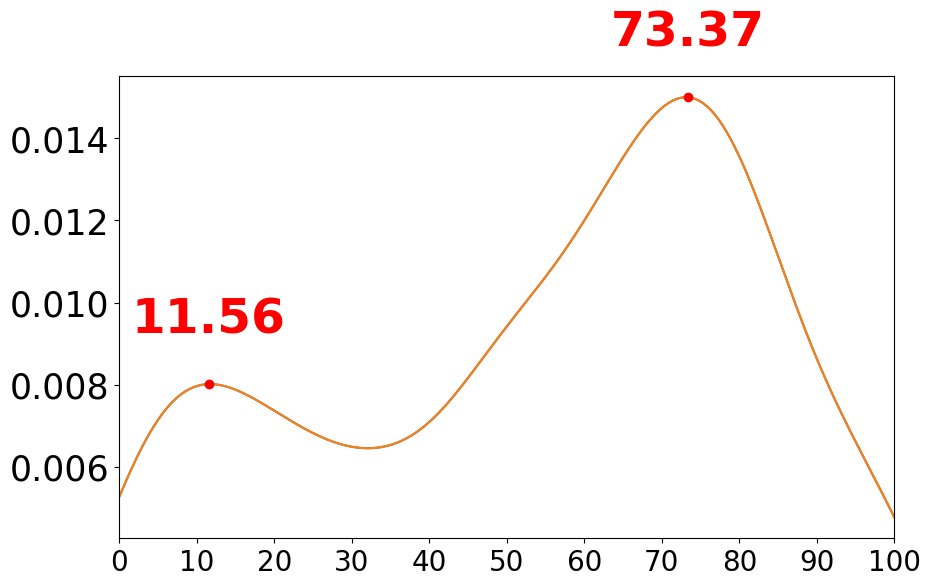

Peak values are at: [11.55778894 73.36683417]


In [57]:
kde_plot(student_25, 0, 100, 0.001, 11, 'Student P(doom) 2025.png', "Estimation", "Density") # peak font size 25

In [58]:
faculty_25.dtype

dtype('O')

In [59]:
faculty_25 = pd.to_numeric(faculty_25, errors='coerce')

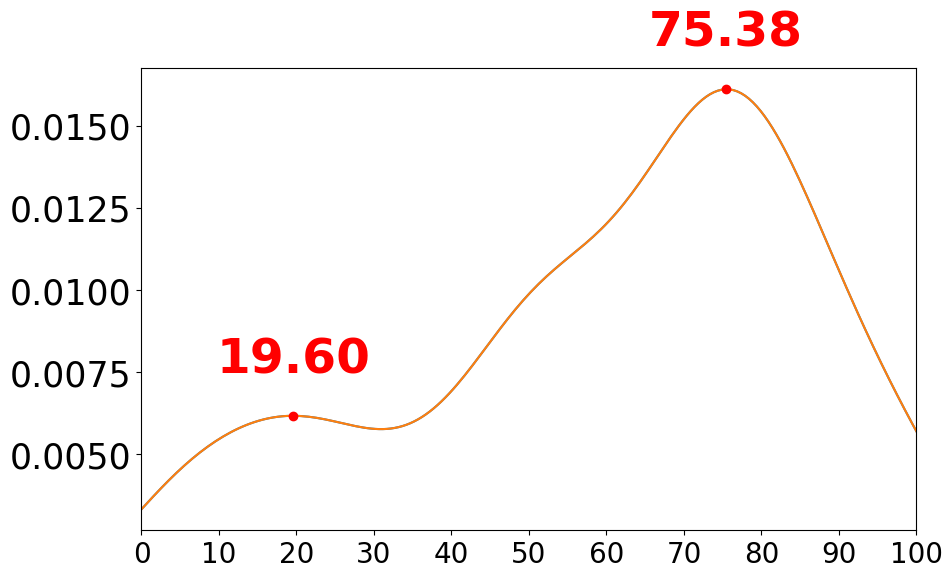

Peak values are at: [19.59798995 75.37688442]


In [92]:
kde_plot(faculty_25, 0, 100, 0.001, 11, 'Faculty P(doom) 2025.png', "Estimation", "Density") # peak font size 25

In [73]:
p_doom_var_26 = "[Q15] If you would like please share your own estimate for p(doom) by entering a number between 0 and 100; do not include the percent sign (%). (Optional)0 means that there is no chance whatsoever of AI causing catastrophic outcomes and 100 means that AI will definitely have catastrophic outcomes for humanity."

In [74]:
student_26 = df_26.loc[role_26 == 1, p_doom_var_26]
faculty_26 = df_26.loc[role_26 == 2, p_doom_var_26]

In [75]:
print(len(faculty_26))
print(faculty_26.isna().sum())

281
25


In [76]:
print(len(student_26))
print(student_26.isna().sum())

727
73


In [77]:
faculty_26 = faculty_26.dropna()
print(len(faculty_26))
print(faculty_26.isna().sum())

256
0


In [78]:
student_26 = student_26.dropna()
print(len(student_26))
print(student_26.isna().sum())

654
0


In [79]:
student_26.dtype

dtype('O')

In [80]:
student_26 = pd.to_numeric(student_26, errors='coerce')

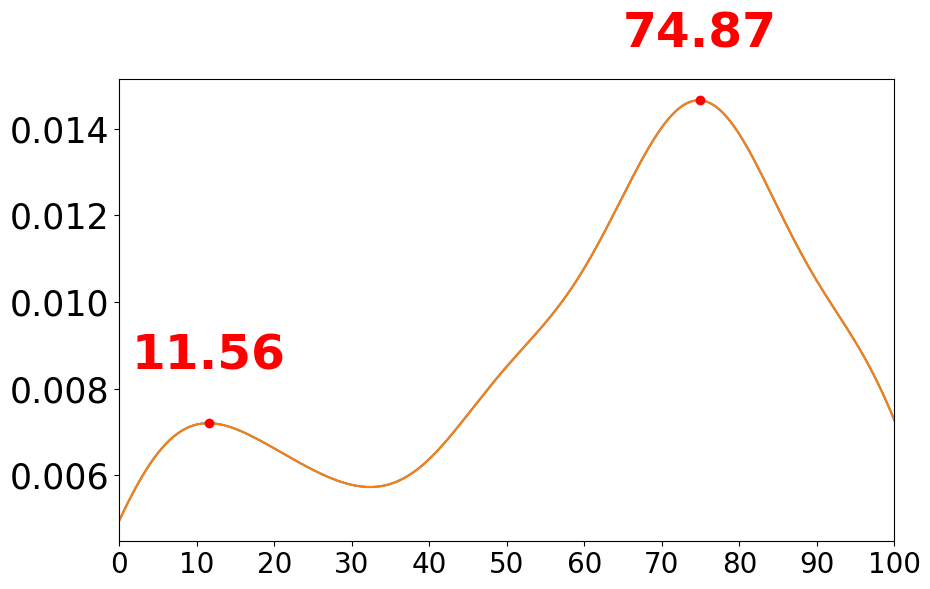

Peak values are at: [11.55778894 74.87437186]


In [93]:
kde_plot(student_26, 0, 100, 0.001, 11, 'Student P(doom) 2026.png', "Estimation", "Density") # peak font size 25

In [83]:
faculty_26.dtype

dtype('O')

In [84]:
faculty_26 = pd.to_numeric(faculty_26, errors='coerce')

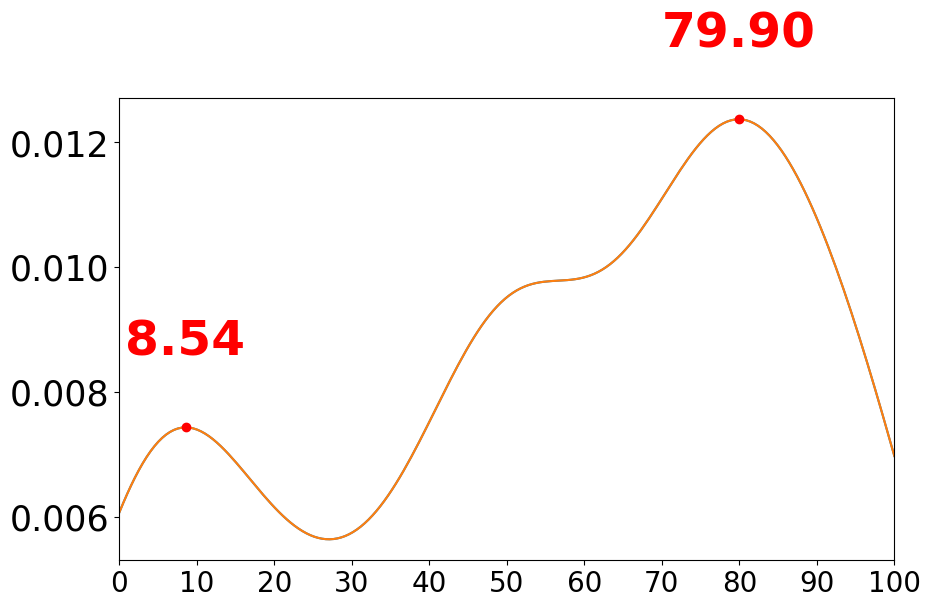

Peak values are at: [ 8.54271357 79.89949749]


In [85]:
kde_plot(faculty_26, 0, 100, 0.001, 11, 'Student P(doom) 2025.png', "Estimation", "Density") # peak font size 25

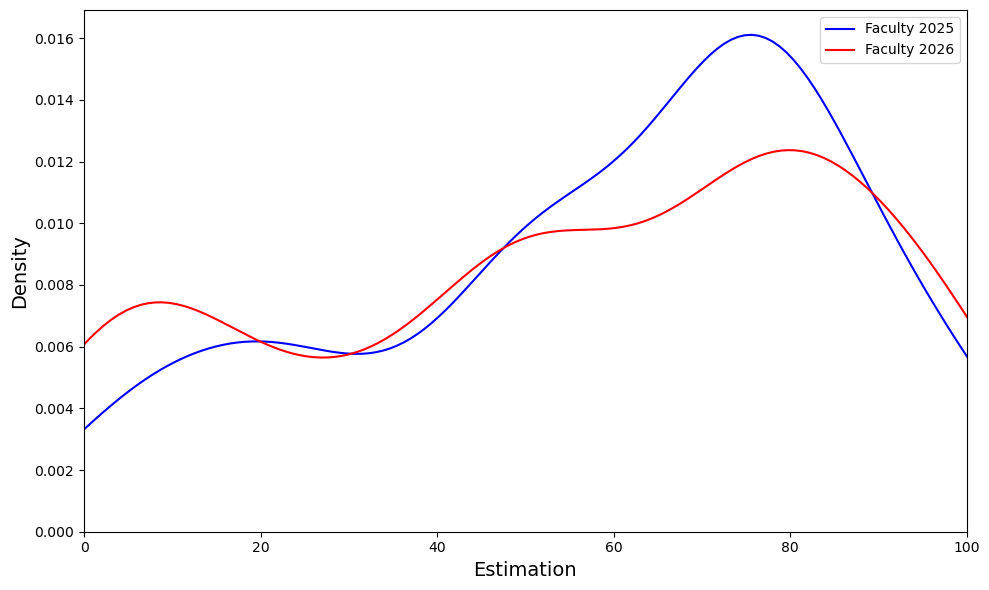

In [103]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.kdeplot(faculty_25, color='blue', label='Faculty 2025')
sns.kdeplot(faculty_26, color='red', label='Faculty 2026')
# sns.kdeplot(student_25, color='green', label='Student 2025')
# sns.kdeplot(student_26, color='purple', label='Student 2026')


plt.xlim(0, 100)
plt.xlabel("Estimation", fontsize=14)
plt.ylabel("Density", fontsize=14)
plt.legend()
plt.tight_layout()
plt.savefig('Faculty_Estimation_2025_2026.png', dpi=300)
plt.show()

In [90]:
print(student_25.describe())

count    794.000000
mean      54.090923
std       28.900930
min        0.000000
25%       30.000000
50%       60.000000
75%       75.000000
max      110.000000
Name: If you would like, please share your own estimate for p(doom) by entering a number between 0 and 100; do not include the percent sign (%). (Optional)0 means that there is no chance whatsoever of AI causing catastrophic outcomes, and 100 means that AI will definitely have catastrophic outcomes for humanity., dtype: float64


In [91]:
print(student_26.describe())

count    648.000000
mean      57.473765
std       30.000555
min        0.000000
25%       33.000000
50%       65.000000
75%       80.000000
max      100.000000
Name: [Q15] If you would like please share your own estimate for p(doom) by entering a number between 0 and 100; do not include the percent sign (%). (Optional)0 means that there is no chance whatsoever of AI causing catastrophic outcomes and 100 means that AI will definitely have catastrophic outcomes for humanity., dtype: float64


In [96]:
# Remove missing values and ensure numeric data
x = student_25.dropna().astype(float)
y = student_26.dropna().astype(float)

# Descriptive statistics
print(f"2025: n={len(x)}, mean={x.mean():.4f}, SD={x.std(ddof=1):.4f}")
print(f"2026: n={len(y)}, mean={y.mean():.4f}, SD={y.std(ddof=1):.4f}")

# Welch's independent-samples t-test
result = stats.ttest_ind(y, x, equal_var=False)

# Mean difference: 2026 - 2025
diff = y.mean() - x.mean()

# Welch-Satterthwaite degrees of freedom
a = y.var(ddof=1) / len(y)
b = x.var(ddof=1) / len(x)
df = (a + b)**2 / (
    a**2 / (len(y) - 1) + b**2 / (len(x) - 1)
)

# 95% confidence interval for the mean difference
se = np.sqrt(a + b)
critical_t = stats.t.ppf(0.975, df)
ci_low = diff - critical_t * se
ci_high = diff + critical_t * se

# Hedges' g (pooled-SD standardized effect size)
n1, n2 = len(x), len(y)
pooled_sd = np.sqrt(
    ((n1 - 1) * x.var(ddof=1) +
     (n2 - 1) * y.var(ddof=1)) /
    (n1 + n2 - 2)
)
d = diff / pooled_sd
J = 1 - 3 / (4 * (n1 + n2) - 9)
hedges_g = J * d

print(f"Mean difference (2026 - 2025): {diff:.4f}")
print(f"95% CI: [{ci_low:.4f}, {ci_high:.4f}]")
print(f"Welch's t({df:.2f}) = {result.statistic:.3f}")
print(f"p-value = {result.pvalue:.4g}")
print(f"Hedges' g = {hedges_g:.3f}")

2025: n=794, mean=54.0909, SD=28.9009
2026: n=648, mean=57.4738, SD=30.0006
Mean difference (2026 - 2025): 3.3828
95% CI: [0.3180, 6.4477]
Welch's t(1361.15) = 2.165
p-value = 0.03054
Hedges' g = 0.115


Students’ mean P(doom) ratings were significantly higher in 2026 (*M* = 57.47, *SD* = 30.00, *n* = 648) than in 2025 (*M* = 54.09, *SD* = 28.90, *n* = 794), according to Welch’s independent-samples *t*-test, *t*(1361.15) = 2.17, *p* = .031. The mean difference (2026 − 2025) was 3.38 points (95% CI [0.32, 6.45]), with a small standardized effect size (Hedges’ *g* = 0.115).

In [99]:
result = stats.mannwhitneyu(
    student_26.dropna(),
    student_25.dropna(),
    alternative="greater",
    method="asymptotic"
)

print("U statistic:", result.statistic)
print("p-value:", result.pvalue)

U statistic: 276524.0
p-value: 0.0070859908938513015


A one-sided Mann–Whitney U test indicated that student P(doom) ratings tended to be higher in 2026 than in 2025 (*U* = 276,524, *p* = .007). The magnitude of this difference was evaluated using an effect-size measure.

Student P(doom) ratings were higher in the 2026 survey than in the 2025 survey. The mean rating increased from 54.09 (*SD* = 28.90, *n* = 794) in 2025 to 57.47 (*SD* = 30.00, *n* = 648) in 2026, a difference of 3.38 points (95% CI [0.32, 6.45]). Welch’s independent-samples *t*-test indicated that this difference was statistically significant, *t*(1361.15) = 2.17, *p* = .031, although the standardized effect was small (Hedges’ *g* = 0.115). A one-sided Mann–Whitney U test also indicated that ratings tended to be higher in 2026 (*U* = 276,524, *p* = .007). Together, these findings suggest a modest upward shift in students’ P(doom) ratings between the two survey waves.

In [102]:
print(faculty_25.describe())
print(faculty_26.describe())

count    195.000000
mean      59.153846
std       27.269501
min        0.000000
25%       42.500000
50%       67.000000
75%       80.000000
max      100.000000
Name: If you would like, please share your own estimate for p(doom) by entering a number between 0 and 100; do not include the percent sign (%). (Optional)0 means that there is no chance whatsoever of AI causing catastrophic outcomes, and 100 means that AI will definitely have catastrophic outcomes for humanity., dtype: float64
count    254.000000
mean      55.188976
std       31.433154
min        0.000000
25%       30.000000
50%       60.000000
75%       80.000000
max      100.000000
Name: [Q15] If you would like please share your own estimate for p(doom) by entering a number between 0 and 100; do not include the percent sign (%). (Optional)0 means that there is no chance whatsoever of AI causing catastrophic outcomes and 100 means that AI will definitely have catastrophic outcomes for humanity., dtype: float64


In [100]:
def welch_t_test(x, y):
    # Descriptive statistics
    print(f"2025: n={len(x)}, mean={x.mean():.4f}, SD={x.std(ddof=1):.4f}")
    print(f"2026: n={len(y)}, mean={y.mean():.4f}, SD={y.std(ddof=1):.4f}")
    
    # Welch's independent-samples t-test
    result = stats.ttest_ind(y, x, equal_var=False)
    
    # Mean difference: y - x
    diff = y.mean() - x.mean()

    # Welch-Satterthwaite degrees of freedom
    a = y.var(ddof=1) / len(y)
    b = x.var(ddof=1) / len(x)
    df = (a + b)**2 / (
        a**2 / (len(y) - 1) + b**2 / (len(x) - 1)
    )
    
    # 95% confidence interval for the mean difference
    se = np.sqrt(a + b)
    critical_t = stats.t.ppf(0.975, df)
    ci_low = diff - critical_t * se
    ci_high = diff + critical_t * se
    
    # Hedges' g (pooled-SD standardized effect size)
    n1, n2 = len(x), len(y)
    pooled_sd = np.sqrt(
        ((n1 - 1) * x.var(ddof=1) +
         (n2 - 1) * y.var(ddof=1)) /
        (n1 + n2 - 2)
    )
    d = diff / pooled_sd
    J = 1 - 3 / (4 * (n1 + n2) - 9)
    hedges_g = J * d
    
    print(f"Mean difference (2026 - 2025): {diff:.4f}")
    print(f"95% CI: [{ci_low:.4f}, {ci_high:.4f}]")
    print(f"Welch's t({df:.2f}) = {result.statistic:.3f}")
    print(f"p-value = {result.pvalue:.4g}")
    print(f"Hedges' g = {hedges_g:.3f}")

In [106]:
x = faculty_25.dropna().astype(float)
y = faculty_26.dropna().astype(float)
welch_t_test(x, y)

2025: n=195, mean=59.1538, SD=27.2695
2026: n=254, mean=55.1890, SD=31.4332
Mean difference (2026 - 2025): -3.9649
95% CI: [-9.4197, 1.4900]
Welch's t(440.32) = -1.429
p-value = 0.1538
Hedges' g = -0.133


In [115]:
def mann_w(x, y):
    result = stats.mannwhitneyu(
    y.dropna(),
    x.dropna(),
    alternative="greater",
    method="asymptotic"
    )

    print("U statistic:", result.statistic)
    print("p-value:", result.pvalue)

In [116]:
mann_w(faculty_25, faculty_26)

U statistic: 23354.5
p-value: 0.8503873063034366


## Harm Vs Beneficial

In [117]:
comp_task_var_26 = "[Q6] Your efficiency at completing tasks"

In [120]:
student_com_26 = df_26.loc[role_26 == 1, comp_task_var_26]

In [121]:
print(len(student_com_26))
print(student_com_26.isna().sum())

727
0


In [136]:
comp_task_var_25 = "Please rate your current feelings on whether GenAI will be harmful or\xa0beneficial\xa0for....2"

In [137]:
student_com_25 = df_25.loc[role_25 == 1, comp_task_var_25]

In [138]:
print(len(student_com_25))
print(student_com_25.isna().sum())

1061
0


In [139]:
def plot_distribution(data, title="Distribution", xlabel="Rating", bins=None):
    # Convert values to numeric and remove missing values
    values = pd.to_numeric(pd.Series(data).squeeze(), errors="coerce").dropna()

    plt.figure(figsize=(9, 5))

    if bins is None:
        sns.histplot(values, discrete=True, edgecolor="black")
    else:
        sns.histplot(values, bins=bins, edgecolor="black")

    plt.title(title, fontsize=14)
    plt.xlabel(xlabel, fontsize=12)
    plt.ylabel("Number of responses", fontsize=12)
    plt.tight_layout()
    plt.show()

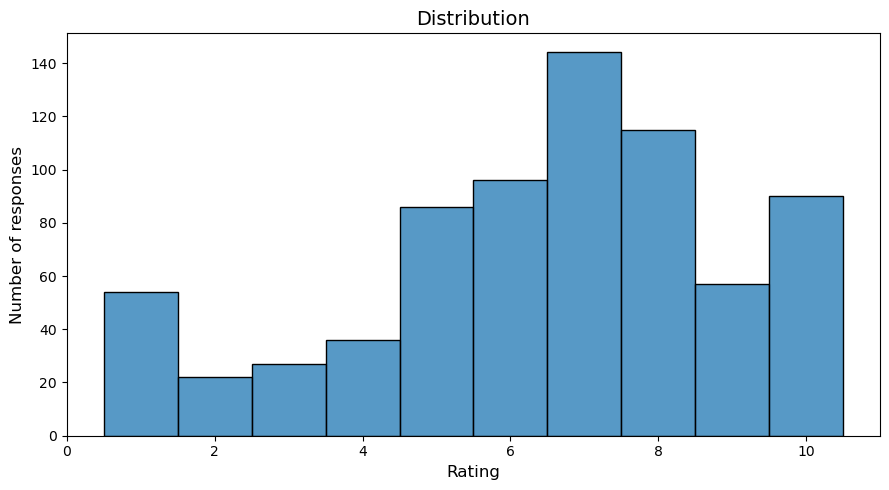

In [140]:
plot_distribution(student_com_26)

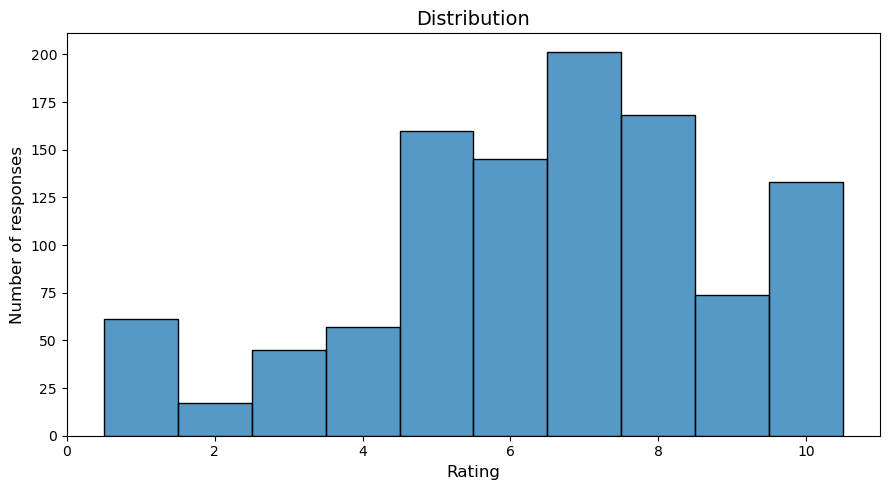

In [141]:
plot_distribution(student_com_25)

In [144]:
def rating_frequency(data, title="Rating Frequency", xlabel="Rating (1–10)"):
    ratings = pd.to_numeric(pd.Series(data).squeeze(), errors="coerce").dropna()

    frequencies = ratings.value_counts().reindex(range(1, 11), fill_value=0)

    plt.figure(figsize=(9, 5))
    bars = plt.bar(frequencies.index, frequencies.values, edgecolor="black")

    # Show frequency above each bar
    plt.bar_label(bars, fmt='%d', padding=3, fontsize=10)

    plt.xticks(range(1, 11))
    plt.xlabel(xlabel, fontsize=12)
    plt.ylabel("Frequency (number of responses)", fontsize=12)
    plt.title(title, fontsize=14)
    plt.ylim(0, max(frequencies.max() * 1.15, 1))
    plt.tight_layout()
    plt.show()

    print(frequencies)

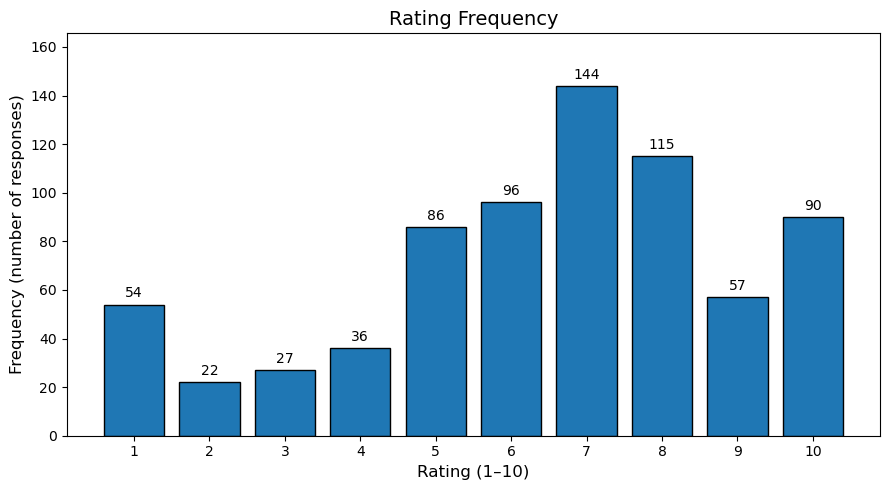

[Q6] Your efficiency at completing tasks
1      54
2      22
3      27
4      36
5      86
6      96
7     144
8     115
9      57
10     90
Name: count, dtype: int64


In [147]:
rating_frequency(student_com_26)

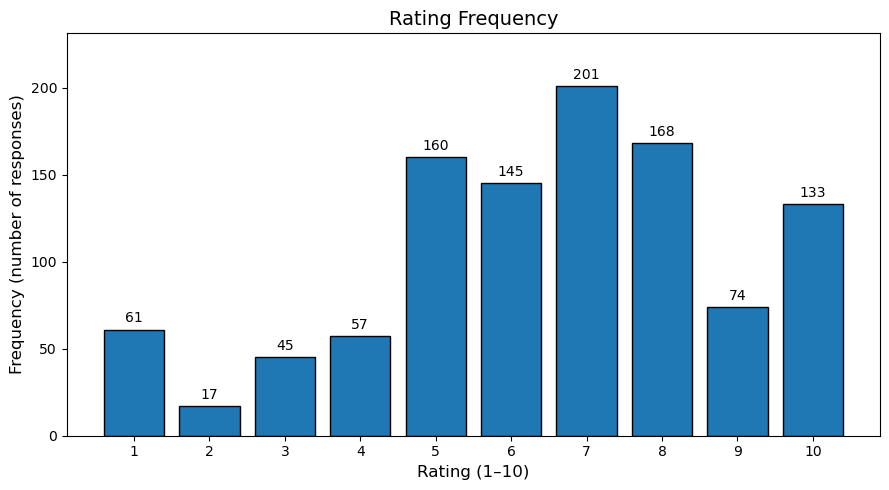

Please rate your current feelings on whether GenAI will be harmful or beneficial for....2
1      61
2      17
3      45
4      57
5     160
6     145
7     201
8     168
9      74
10    133
Name: count, dtype: int64


In [148]:
rating_frequency(student_com_25)

In [149]:
x = student_com_25.dropna().astype(float)
y = student_com_26.dropna().astype(float)
welch_t_test(x, y)

2025: n=1061, mean=6.4797, SD=2.3817
2026: n=727, mean=6.4237, SD=2.5176
Mean difference (2026 - 2025): -0.0561
95% CI: [-0.2887, 0.1766]
Welch's t(1502.46) = -0.473
p-value = 0.6364
Hedges' g = -0.023


In [150]:
quality_task_var_26 = "[Q6] The quality of tasks you complete"

In [151]:
student_quality_26 = df_26.loc[role_26 == 1, quality_task_var_26]

In [152]:
print(len(student_quality_26))
print(student_quality_26.isna().sum())

727
0


In [153]:
quality_task_var_25 = "Please rate your current feelings on whether GenAI will be harmful or\xa0beneficial\xa0for....3"

In [154]:
student_quality_25 = df_25.loc[role_25 == 1, quality_task_var_25]

In [155]:
print(len(student_quality_25))
print(student_quality_25.isna().sum())

1061
0


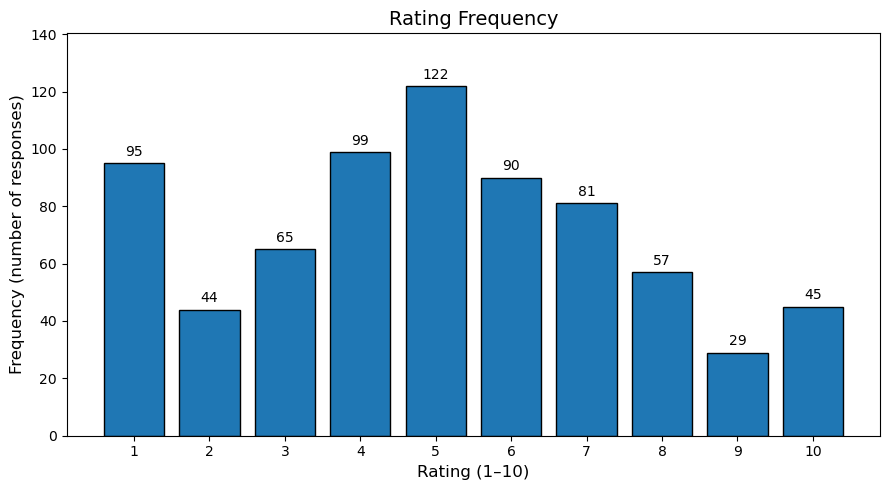

[Q6] The quality of tasks you complete
1      95
2      44
3      65
4      99
5     122
6      90
7      81
8      57
9      29
10     45
Name: count, dtype: int64


In [157]:
rating_frequency(student_quality_26)

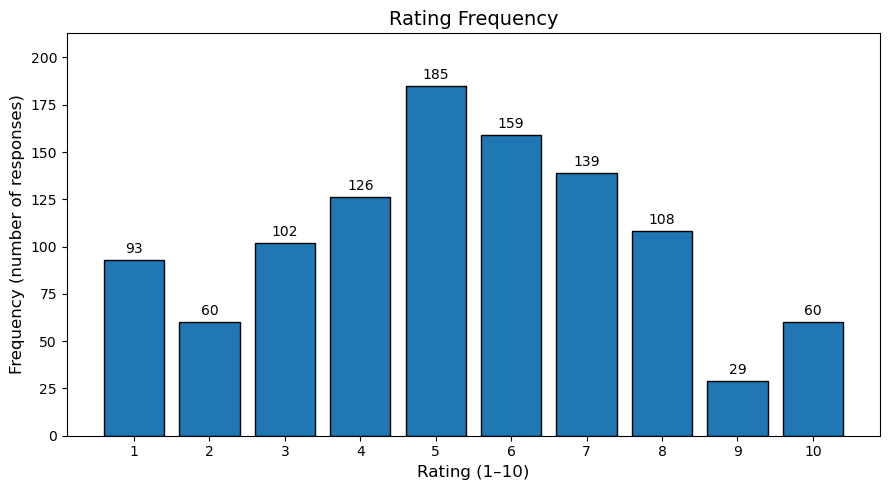

Please rate your current feelings on whether GenAI will be harmful or beneficial for....3
1      93
2      60
3     102
4     126
5     185
6     159
7     139
8     108
9      29
10     60
Name: count, dtype: int64


In [158]:
rating_frequency(student_quality_25)

In [160]:
x = student_quality_25.dropna().astype(float)
y = student_quality_26.dropna().astype(float)
welch_t_test(x, y)

2025: n=1061, mean=5.2780, SD=2.4050
2026: n=727, mean=5.0316, SD=2.5687
Mean difference (2026 - 2025): -0.2464
95% CI: [-0.4828, -0.0100]
Welch's t(1491.51) = -2.044
p-value = 0.0411
Hedges' g = -0.100


In [161]:
society_var_26 = "[Q6] Society at large"

In [162]:
student_society_26 = df_26.loc[role_26 == 1, society_var_26]

In [163]:
print(len(student_society_26))
print(student_society_26.isna().sum())

727
0


In [165]:
society_var_25 = "Please rate your current feelings on whether GenAI will be harmful or\xa0beneficial\xa0for....6"

In [166]:
student_society_25 = df_25.loc[role_25 == 1, society_var_25]

In [167]:
print(len(student_society_25))
print(student_society_25.isna().sum())

1061
0


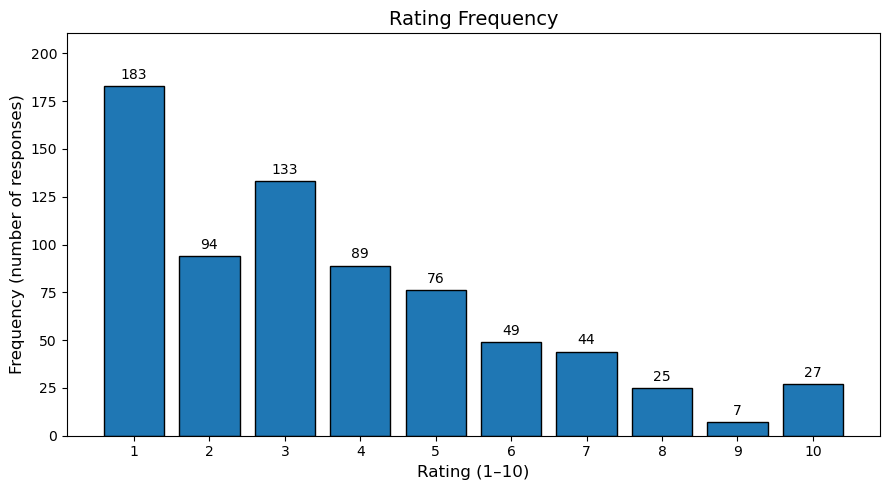

[Q6] Society at large
1     183
2      94
3     133
4      89
5      76
6      49
7      44
8      25
9       7
10     27
Name: count, dtype: int64


In [168]:
rating_frequency(student_society_26)

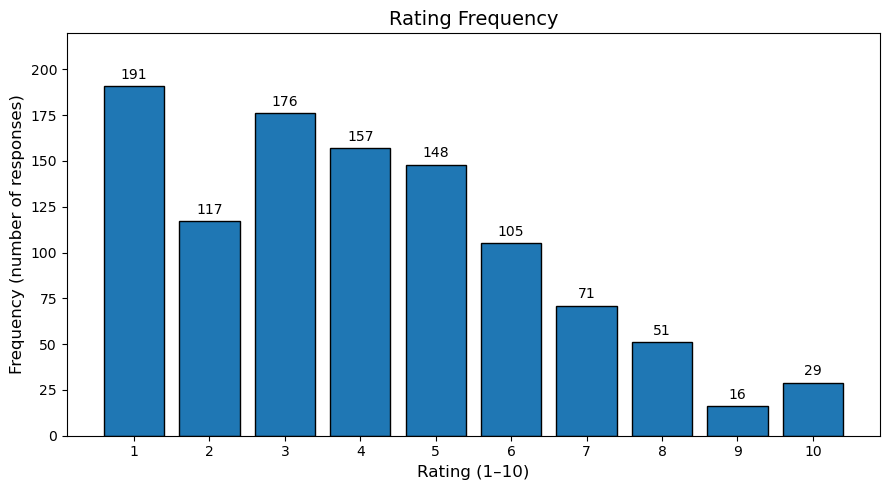

Please rate your current feelings on whether GenAI will be harmful or beneficial for....6
1     191
2     117
3     176
4     157
5     148
6     105
7      71
8      51
9      16
10     29
Name: count, dtype: int64


In [169]:
rating_frequency(student_society_25)

In [170]:
x = student_society_25.dropna().astype(float)
y = student_society_26.dropna().astype(float)
welch_t_test(x, y)

2025: n=1061, mean=4.0434, SD=2.3448
2026: n=727, mean=3.6327, SD=2.4260
Mean difference (2026 - 2025): -0.4106
95% CI: [-0.6366, -0.1846]
Welch's t(1524.94) = -3.563
p-value = 0.0003772
Hedges' g = -0.173


In [171]:
learning_var_26 = "[Q6] Your learning during higher education"

In [172]:
student_lear_26 = df_26.loc[role_26 == 1, learning_var_26]

In [173]:
print(len(student_lear_26))
print(student_lear_26.isna().sum())

727
0


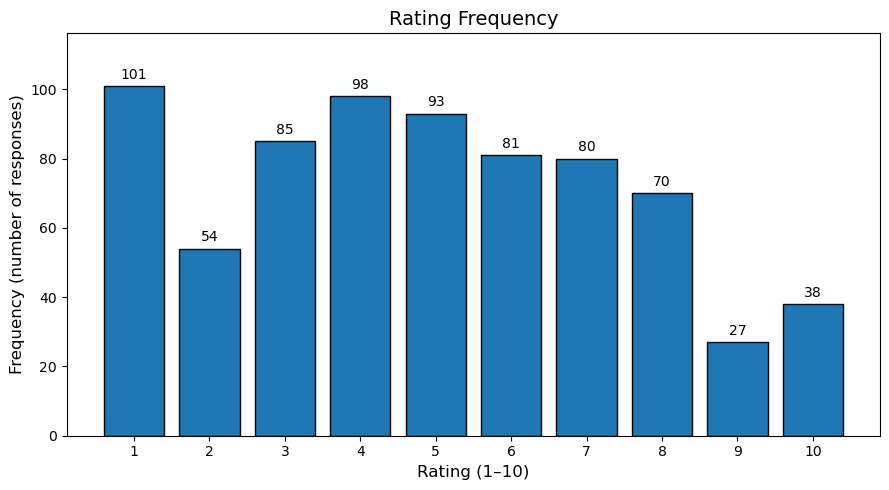

[Q6] Your learning during higher education
1     101
2      54
3      85
4      98
5      93
6      81
7      80
8      70
9      27
10     38
Name: count, dtype: int64


In [174]:
rating_frequency(student_lear_26)

In [175]:
learning_var_25 = "Please rate your current feelings on whether GenAI will be harmful or\xa0beneficial\xa0for....1"

In [176]:
student_lear_25 = df_25.loc[role_25 == 1, learning_var_25]

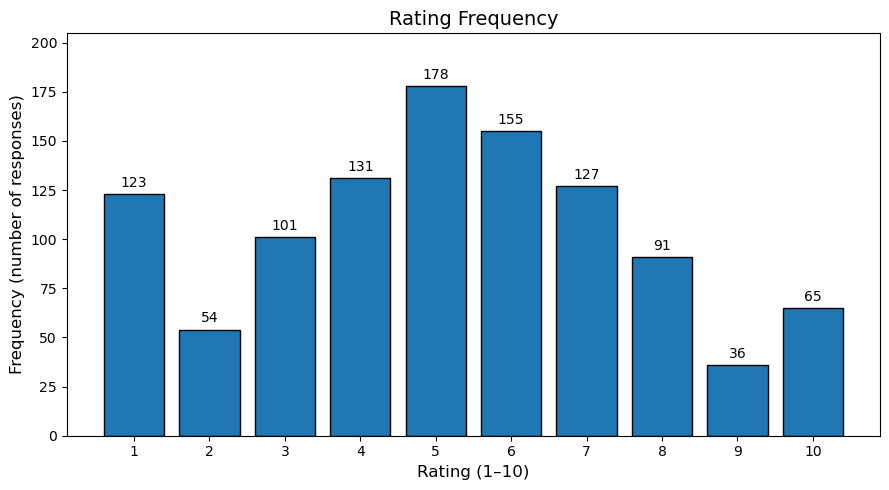

Please rate your current feelings on whether GenAI will be harmful or beneficial for....1
1     123
2      54
3     101
4     131
5     178
6     155
7     127
8      91
9      36
10     65
Name: count, dtype: int64


In [177]:
rating_frequency(student_lear_25)

In [179]:
x = student_lear_25.dropna().astype(float)
y = student_lear_26.dropna().astype(float)
welch_t_test(x, y)

2025: n=1061, mean=5.1546, SD=2.5041
2026: n=727, mean=4.8831, SD=2.6093
Mean difference (2026 - 2025): -0.2715
95% CI: [-0.5139, -0.0291]
Welch's t(1517.49) = -2.197
p-value = 0.0282
Hedges' g = -0.107


Statistical Significance ($p = 0.0282$): Since $p < 0.05$, there is a statistically significant decrease in rating from 2025 to 2026. Sampling noise alone is an unlikely explanation for this drop.

Precision ($95\%\text{ CI } = [-0.5139, -0.0291]$): The interval stays entirely below zero, confirming a true negative shift. It tells us we can be 95% confident that the true population decrease is between roughly $0.03$ and $0.51$ points.

Practical Impact ($\text{Hedges' } g = -0.107$): Despite being statistically significant, the effect size is tiny ($\vert{}g\vert{} < 0.20$). A change of less than a third of a point on a scale where the standard deviation is over $2.5$ represents a very minor real-world shift.

## GenAI Usage

In [180]:
usage_var_26 = "[Q5] LLM-powered chatbotsÂ\xa0accessed through a browser or app (e.g. ChatGPT.com Claude.ai Gemini.google.com)"

In [182]:
student_usage_26 = df_26.loc[role_26 == 1, usage_var_26]

In [184]:
print(len(student_usage_26))
print(student_usage_26.isna().sum())

727
0


In [185]:
print(student_usage_26.value_counts()/len(student_usage_26) * 100)

[Q5] LLM-powered chatbotsÂ accessed through a browser or app (e.g. ChatGPT.com Claude.ai Gemini.google.com)
4    34.112792
5    28.748281
3    18.019257
1     9.491059
2     7.702889
6     1.925722
Name: count, dtype: float64


In [188]:
usage_var_25 = "How frequently have you used the following GenAI-based tools so far this semester for your classes, research, and/or any other professional efforts?"

In [189]:
student_usage_25 = df_25.loc[role_25 == 1, usage_var_25]

In [190]:
print(len(student_usage_25))
print(student_usage_25.isna().sum())

1061
0


In [191]:
print(student_usage_25.value_counts()/len(student_usage_25) * 100)

How frequently have you used the following GenAI-based tools so far this semester for your classes, research, and/or any other professional efforts?
3    39.019793
4    22.243167
2    19.604147
1     8.105561
6     7.540057
5     3.487276
Name: count, dtype: float64


In [193]:
genai_usage = {
    1: 'Never',
    2: 'Not this Semester',
    3: 'Irregular',
    4: 'Regular',
    5: 'Super User',
    6: 'Fun'
}

In [201]:
def plot_usage_distribution(data_25, data_26):
    categories = list(genai_usage.keys())

    # Calculate percentages, including categories with zero responses
    pct_25 = (
        pd.to_numeric(data_25, errors='coerce')
        .value_counts(normalize=True).reindex(categories, fill_value=0) * 100
    )
    pct_26 = (
        pd.to_numeric(data_26, errors='coerce')
        .value_counts(normalize=True).reindex(categories, fill_value=0) * 100
    )

    plt.figure(figsize=(10, 6))

    plt.plot(categories, pct_25, marker='o', linewidth=2,
             markersize=7, label='2025')
    plt.plot(categories, pct_26, marker='o', linewidth=2,
             markersize=7, label='2026')

    # Display percentages next to each point
    for x in categories:
        plt.annotate(f'{pct_25[x]:.1f}%',
                     (x, pct_25[x]), xytext=(0, 8),
                     textcoords='offset points', ha='center', fontsize=9)
        plt.annotate(f'{pct_26[x]:.1f}%',
                     (x, pct_26[x]), xytext=(0, -15),
                     textcoords='offset points', ha='center', fontsize=9)

    plt.xticks(categories, [genai_usage[x] for x in categories], rotation=20)
    plt.xlabel('GenAI Usage Frequency', fontsize=12)
    plt.ylabel('Percentage of Respondents (%)', fontsize=12)
    plt.title('GenAI Usage Frequency: 2025 vs. 2026', fontsize=14)
    plt.legend()
    plt.grid(axis='y', linestyle='--', alpha=0.4)
    plt.tight_layout()
    plt.show()

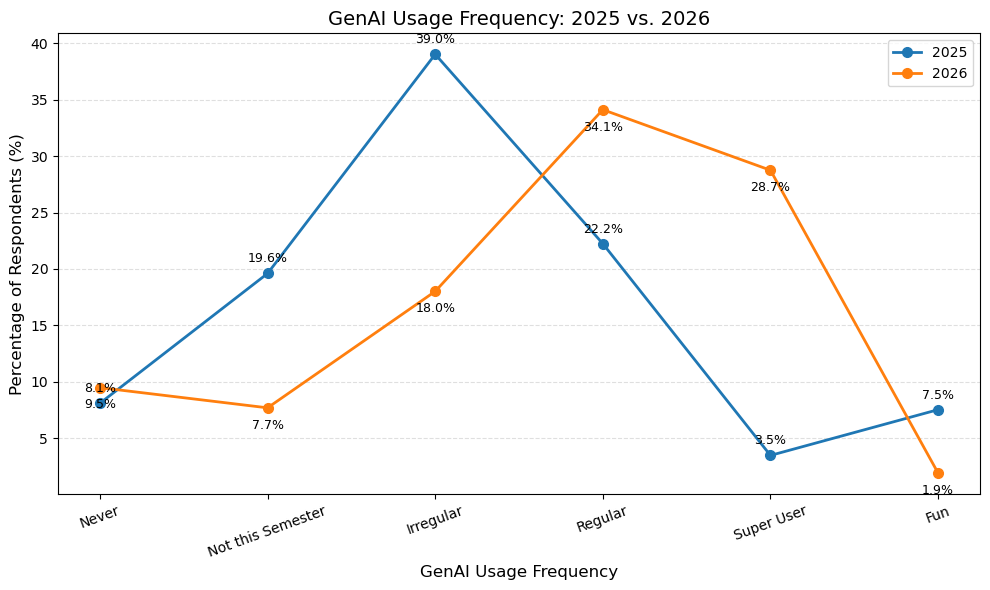

In [202]:
plot_usage_distribution(student_usage_25, student_usage_26)

In [203]:
faculty_usage_26 = df_26.loc[role_26 == 2, usage_var_26]

In [204]:
print(faculty_usage_26.value_counts())

[Q5] LLM-powered chatbotsÂ accessed through a browser or app (e.g. ChatGPT.com Claude.ai Gemini.google.com)
4    89
5    67
3    65
2    26
1    24
6    10
Name: count, dtype: int64


In [205]:
faculty_usage_25 = df_25.loc[role_25 == 2, usage_var_25]

In [206]:
print(faculty_usage_25.value_counts())

How frequently have you used the following GenAI-based tools so far this semester for your classes, research, and/or any other professional efforts?
2    89
3    82
4    51
6    35
1    20
5     7
Name: count, dtype: int64


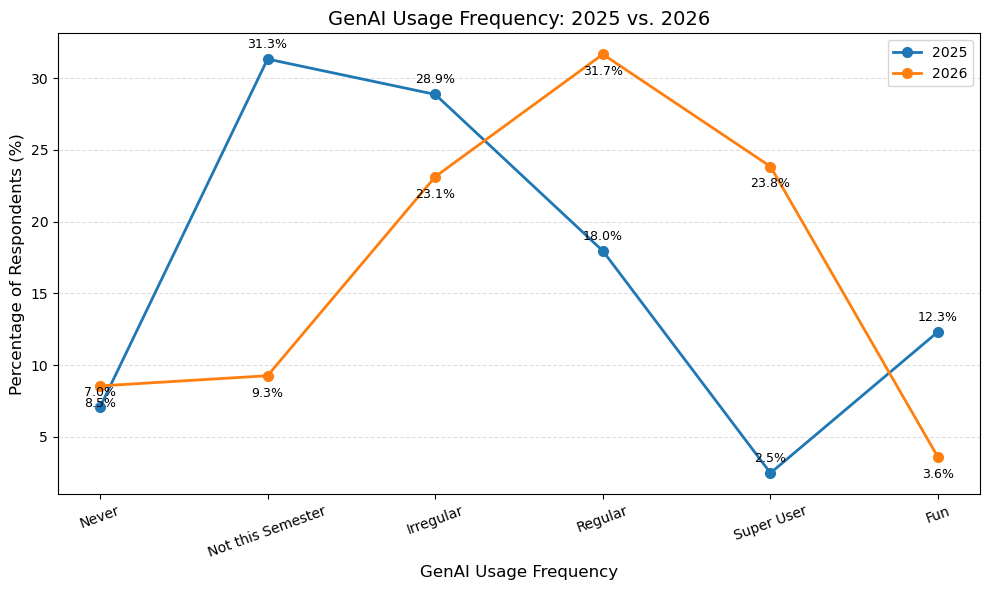

In [207]:
plot_usage_distribution(faculty_usage_25, faculty_usage_26)

## Concerns

In [349]:
concern_cols_26 = df_26.columns[162:180]

In [350]:
concern_mapping_26 = {
    162: 'No concern',
    163: 'Misinfo.',
    164: 'Climate impacts',
    165: 'Privacy breaches',
    166: 'Dishonest use',
    167: 'Job displacement',
    168: 'Power concentration',
    169: 'Increasing digital divide',
    170: 'Biased training data',
    171: 'Discriminatory outputs',
    172: 'Incentivizing laziness',
    173: 'Reducing social connection',
    174: 'Replacing real learning',
    175: 'Damaging human creativity',
    176: 'Assesment design issue',
    177: 'Gaps in policy and governance',
    178: 'Copy right violation',
    179: 'something else'
}

In [351]:
concern_cols_26

Index(['[Q13] What are your most important concerns related to GenAI? Select up to 3 options below.',
       'Unnamed: 163', 'Unnamed: 164', 'Unnamed: 165', 'Unnamed: 166',
       'Unnamed: 167', 'Unnamed: 168', 'Unnamed: 169', 'Unnamed: 170',
       'Unnamed: 171', 'Unnamed: 172', 'Unnamed: 173', 'Unnamed: 174',
       'Unnamed: 175', 'Unnamed: 176', 'Unnamed: 177', 'Unnamed: 178',
       'Unnamed: 179'],
      dtype='object')

In [352]:
counts_26 = (
    df_26[concern_cols_26].apply(pd.to_numeric, errors='coerce').eq(1).sum()
)

In [353]:
print(counts_26)

[Q13] What are your most important concerns related to GenAI? Select up to 3 options below.      7
Unnamed: 163                                                                                   335
Unnamed: 164                                                                                   378
Unnamed: 165                                                                                    99
Unnamed: 166                                                                                   165
Unnamed: 167                                                                                   176
Unnamed: 168                                                                                   151
Unnamed: 169                                                                                    25
Unnamed: 170                                                                                    81
Unnamed: 171                                                                                    45
Unnamed: 1

In [354]:
student_concern_26 = df_26.loc[role_26 == 1, concern_cols_26].apply(pd.to_numeric, errors = 'coerce').eq(1).sum()

In [355]:
print(student_concern_26)

[Q13] What are your most important concerns related to GenAI? Select up to 3 options below.      6
Unnamed: 163                                                                                   238
Unnamed: 164                                                                                   281
Unnamed: 165                                                                                    76
Unnamed: 166                                                                                   108
Unnamed: 167                                                                                   125
Unnamed: 168                                                                                    92
Unnamed: 169                                                                                    14
Unnamed: 170                                                                                    59
Unnamed: 171                                                                                    31
Unnamed: 1

In [356]:
student_concern_26.index = [
    concern_mapping_26[df_26.columns.get_loc(col)]
    for col in concern_cols_26
]

In [357]:
print(df_26['Unnamed: 179'].dtype)

object


In [361]:
# count = 0
# for i in df_26['Unnamed: 179']:
#     if not pd.isna(i) and i != '0':
#         #print(i)
#         count += 1
# print(count)


count = 0

for idx, value in enumerate(df_26['Unnamed: 179']):
    if pd.notna(value) and str(value).strip() not in ('', '0'):
        if role_26.iloc[idx] == 1:
            count += 1

print(count)
        

26


In [362]:
other_text = (
    df_26['Unnamed: 179']
    .astype("object")
    .str.strip()
)

In [363]:
#other_text.value_counts()

In [364]:
student_concern_26['something else'] = count

In [365]:
print(student_concern_26.sort_values())

No concern                         6
Increasing digital divide         14
something else                    26
Assesment design issue            30
Discriminatory outputs            31
Biased training data              59
Privacy breaches                  76
Power concentration               92
Copy right violation              96
Reducing social connection       105
Dishonest use                    108
Gaps in policy and governance    121
Job displacement                 125
Incentivizing laziness           195
Misinfo.                         238
Replacing real learning          264
Damaging human creativity        264
Climate impacts                  281
dtype: int64


In [366]:
## Count the number of respondent

In [416]:
concern_data_26 = df_26[concern_cols_26].copy()
concern_data_26.columns = [
    concern_mapping_26[pos] for pos in range(162, 180)
]

In [417]:
regular_cols = [
    col for col in concern_data_26.columns
    if col != "something else"
]

In [418]:
regular_selected = (
    concern_data_26[regular_cols]
    .apply(pd.to_numeric, errors="coerce")
    .eq(1)
)

counts_26 = regular_selected.sum()

In [419]:
print(counts_26)

No concern                         7
Misinfo.                         335
Climate impacts                  378
Privacy breaches                  99
Dishonest use                    165
Job displacement                 176
Power concentration              151
Increasing digital divide         25
Biased training data              81
Discriminatory outputs            45
Incentivizing laziness           243
Reducing social connection       153
Replacing real learning          390
Damaging human creativity        348
Assesment design issue            37
Gaps in policy and governance    155
Copy right violation             128
dtype: int64


In [420]:
# 3. Count "something else" only when actual text is provided
other_text = (
    concern_data_26["something else"]
    .astype("object")
    .str.strip()
)

selected_other = (
    other_text.notna()
    & other_text.ne("")
    & other_text.ne("0")
)

counts_26["something else"] = selected_other.sum()
print(counts_26["something else"])

41


In [421]:
# 4. Count respondents who answered at least one option
# Each respondent is counted only once, even if they chose multiple options
answered_q13 = regular_selected.any(axis=1) | selected_other

print("\n=== Q13 response counts ===")
print("Total respondents:", len(df_26))
print("Respondents who answered:", answered_q13.sum())
print("Respondents who did not answer:", (~answered_q13).sum())

# 5. Count student responses (role == 1)
student_mask = role_26 == 1

print("\n=== Student Q13 response counts ===")
print("Total students:", student_mask.sum())
print("Students who answered:", (answered_q13 & student_mask).sum())
print("Students who did not answer:", ((~answered_q13) & student_mask).sum())

# 6. Count each concern among students
student_concern_26 = regular_selected.loc[student_mask].sum()
student_concern_26["something else"] = selected_other.loc[student_mask].sum()

print("\n=== Student concern selections ===")
print(student_concern_26.sort_values(ascending=False))


=== Q13 response counts ===
Total respondents: 1008
Respondents who answered: 1008
Respondents who did not answer: 0

=== Student Q13 response counts ===
Total students: 727
Students who answered: 727
Students who did not answer: 0

=== Student concern selections ===
Climate impacts                  281
Replacing real learning          264
Damaging human creativity        264
Misinfo.                         238
Incentivizing laziness           195
Job displacement                 125
Gaps in policy and governance    121
Dishonest use                    108
Reducing social connection       105
Copy right violation              96
Power concentration               92
Privacy breaches                  76
Biased training data              59
Discriminatory outputs            31
Assesment design issue            30
something else                    26
Increasing digital divide         14
No concern                         6
dtype: int64


In [373]:
import matplotlib.pyplot as plt
import textwrap

def plot_distribution(
    counts,
    denominator,
    title="Distribution of GenAI Concerns",
    figsize=(10, 7),
    title_fontsize=14,
    label_fontsize=11,
    tick_fontsize=8,
    value_fontsize=10,
    wrap_width=20
):
    percentages = (counts / denominator * 100).sort_values(ascending=True)

    # Wrap concern labels across multiple lines
    labels = [
        textwrap.fill(str(label), width=wrap_width)
        for label in percentages.index
    ]

    fig, ax = plt.subplots(figsize=figsize)

    bars = ax.barh(
        range(len(percentages)),
        percentages.values,
        edgecolor="black"
    )

    # Bold percentage labels at the end of each bar
    ax.bar_label(
        bars,
        labels=[f"{v:.1f}%" for v in percentages.values],
        padding=5,
        fontsize=value_fontsize,
        fontweight="bold"
    )

    # Bold, wrapped concern labels
    ax.set_yticks(range(len(percentages)))
    ax.set_yticklabels(labels, fontsize=tick_fontsize, fontweight="bold")

    # Bold x-axis tick values
    ax.tick_params(axis="x", labelsize=tick_fontsize)
    for tick in ax.get_xticklabels():
        tick.set_fontweight("bold")

    ax.set_xlabel("", fontsize=label_fontsize)
    ax.set_ylabel("")

    ax.set_xlim(0, percentages.max() * 1.20)
    ax.grid(axis="x", linestyle="--", alpha=0.4)
    ax.set_axisbelow(True)

    plt.tight_layout()
    plt.show()

    print(percentages.round(2))

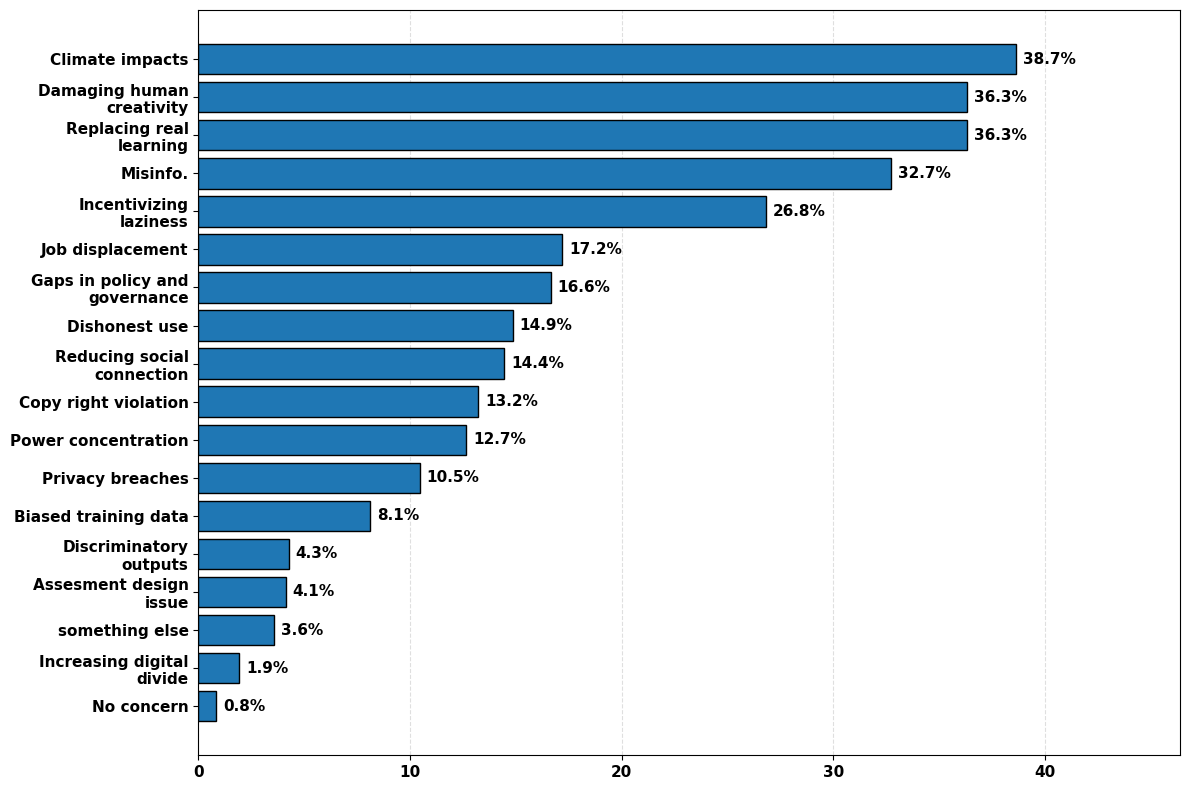

No concern                        0.83
Increasing digital divide         1.93
something else                    3.58
Assesment design issue            4.13
Discriminatory outputs            4.26
Biased training data              8.12
Privacy breaches                 10.45
Power concentration              12.65
Copy right violation             13.20
Reducing social connection       14.44
Dishonest use                    14.86
Gaps in policy and governance    16.64
Job displacement                 17.19
Incentivizing laziness           26.82
Misinfo.                         32.74
Replacing real learning          36.31
Damaging human creativity        36.31
Climate impacts                  38.65
dtype: float64


In [374]:
n_students_answered = (answered_q13 & student_mask).sum()

plot_distribution(
    counts=student_concern_26,
    denominator=n_students_answered,
    title="GenAI Concerns — Students (2026)",
    figsize=(12, 8),
    title_fontsize=16,
    label_fontsize=13,
    tick_fontsize=11,
    value_fontsize=11
)

<h4>Concerns: faculty 2026</h4>

In [430]:
faculty_concern_26 = df_26.loc[role_26 == 2, concern_cols_26].apply(pd.to_numeric, errors = 'coerce').eq(1).sum()

In [431]:
print(faculty_concern_26)

[Q13] What are your most important concerns related to GenAI? Select up to 3 options below.      1
Unnamed: 163                                                                                    97
Unnamed: 164                                                                                    97
Unnamed: 165                                                                                    23
Unnamed: 166                                                                                    57
Unnamed: 167                                                                                    51
Unnamed: 168                                                                                    59
Unnamed: 169                                                                                    11
Unnamed: 170                                                                                    22
Unnamed: 171                                                                                    14
Unnamed: 1

In [432]:
faculty_concern_26.index = [
    concern_mapping_26[df_26.columns.get_loc(col)]
    for col in concern_cols_26
]

In [433]:
count = 0

for idx, value in enumerate(df_26['Unnamed: 179']):
    if pd.notna(value) and str(value).strip() not in ('', '0'):
        if role_26.iloc[idx] == 2:
            count += 1

print(count)
        

15


In [434]:
faculty_concern_26['something else'] = count

In [435]:
print(faculty_concern_26.sort_values())

No concern                         1
Assesment design issue             7
Increasing digital divide         11
Discriminatory outputs            14
something else                    15
Biased training data              22
Privacy breaches                  23
Copy right violation              32
Gaps in policy and governance     34
Incentivizing laziness            48
Reducing social connection        48
Job displacement                  51
Dishonest use                     57
Power concentration               59
Damaging human creativity         84
Climate impacts                   97
Misinfo.                          97
Replacing real learning          126
dtype: int64


In [436]:
# 4. Count respondents who answered at least one option
# Each respondent is counted only once, even if they chose multiple options
answered_q13 = regular_selected.any(axis=1) | selected_other

print("\n=== Q13 response counts ===")
print("Total respondents:", len(df_26))
print("Respondents who answered:", answered_q13.sum())
print("Respondents who did not answer:", (~answered_q13).sum())

# 5. Count faculty responses (role == 2)
faculty_mask = role_26 == 2

print("\n=== Faculty Q13 response counts ===")
print("Total faculty:", faculty_mask.sum())
print("Faculty who answered:", (answered_q13 & faculty_mask).sum())
print("Faculty who did not answer:", ((~answered_q13) & faculty_mask).sum())

# 6. Count each concern among faculty
faculty_concern_26 = regular_selected.loc[faculty_mask].sum()
faculty_concern_26["something else"] = selected_other.loc[faculty_mask].sum()

print("\n=== faculty concern selections ===")
print(faculty_concern_26.sort_values(ascending=False))


=== Q13 response counts ===
Total respondents: 1008
Respondents who answered: 1008
Respondents who did not answer: 0

=== Faculty Q13 response counts ===
Total faculty: 281
Faculty who answered: 281
Faculty who did not answer: 0

=== faculty concern selections ===
Replacing real learning          126
Climate impacts                   97
Misinfo.                          97
Damaging human creativity         84
Power concentration               59
Dishonest use                     57
Job displacement                  51
Incentivizing laziness            48
Reducing social connection        48
Gaps in policy and governance     34
Copy right violation              32
Privacy breaches                  23
Biased training data              22
something else                    15
Discriminatory outputs            14
Increasing digital divide         11
Assesment design issue             7
No concern                         1
dtype: int64


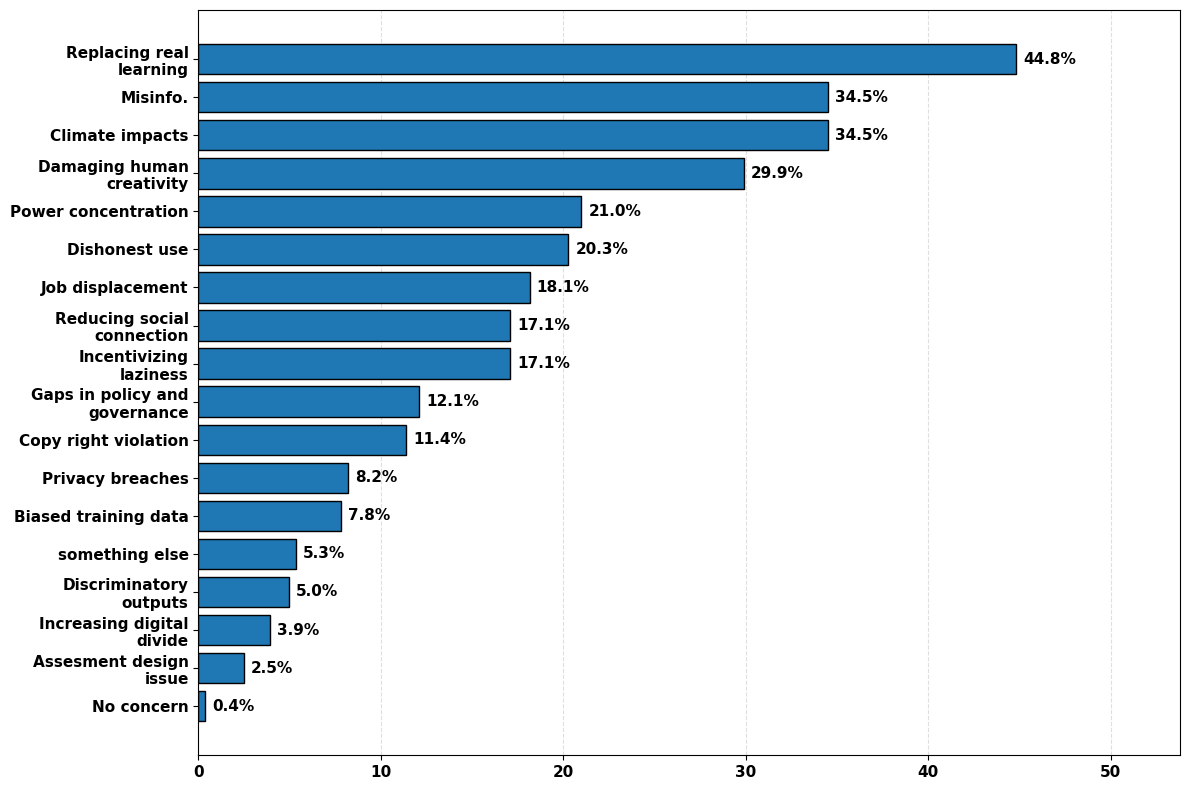

No concern                        0.36
Assesment design issue            2.49
Increasing digital divide         3.91
Discriminatory outputs            4.98
something else                    5.34
Biased training data              7.83
Privacy breaches                  8.19
Copy right violation             11.39
Gaps in policy and governance    12.10
Incentivizing laziness           17.08
Reducing social connection       17.08
Job displacement                 18.15
Dishonest use                    20.28
Power concentration              21.00
Damaging human creativity        29.89
Climate impacts                  34.52
Misinfo.                         34.52
Replacing real learning          44.84
dtype: float64


In [437]:
n_faculty_answered = (answered_q13 & faculty_mask).sum()

plot_distribution(
    counts=faculty_concern_26,
    denominator=n_faculty_answered,
    title="GenAI Concerns — Faculty (2026)",
    figsize=(12, 8),
    title_fontsize=16,
    label_fontsize=13,
    tick_fontsize=11,
    value_fontsize=11
)

<h4 style="color: blue;">Concerns: Student 2025</h4>

In [439]:
concern_mapping_25 = {
    143: 'No concern',
    144: 'Misinfo.',
    145: 'Climate impacts',
    146: 'Privacy breaches',
    147: 'Dishonest use',
    148: 'Job displacement',
    149: 'Power concentration',
    150: 'Increasing digital divide',
    151: 'Biased training data',
    152: 'Discriminatory outputs',
    153: 'Incentivizing laziness',
    154: 'Reducing social connection',
    155: 'Replacing real learning',
    156: 'Damaging human creativity',
    157: 'Assesment design issue',
    158: 'Gaps in policy and governance',
    159: 'something else'
}

In [440]:
concern_cols_25 = df_25.columns[143:160]

In [441]:
concern_cols_25

Index(['What are your most important concerns related to GenAI? Select up to 3 options below.',
       'Unnamed: 144', 'Unnamed: 145', 'Unnamed: 146', 'Unnamed: 147',
       'Unnamed: 148', 'Unnamed: 149', 'Unnamed: 150', 'Unnamed: 151',
       'Unnamed: 152', 'Unnamed: 153', 'Unnamed: 154', 'Unnamed: 155',
       'Unnamed: 156', 'Unnamed: 157', 'Unnamed: 158', 'Unnamed: 159'],
      dtype='object')

In [442]:
counts_25 = (
    df_25[concern_cols_25].apply(pd.to_numeric, errors='coerce').eq(1).sum()
)

In [443]:
print(counts_25)

What are your most important concerns related to GenAI? Select up to 3 options below.     24
Unnamed: 144                                                                             554
Unnamed: 145                                                                             396
Unnamed: 146                                                                             166
Unnamed: 147                                                                             326
Unnamed: 148                                                                             225
Unnamed: 149                                                                             134
Unnamed: 150                                                                              49
Unnamed: 151                                                                             133
Unnamed: 152                                                                              53
Unnamed: 153                                                          

In [444]:
student_concern_25 = df_25.loc[role_25 == 1, concern_cols_25].apply(pd.to_numeric, errors = 'coerce').eq(1).sum()

In [445]:
print(student_concern_25)

What are your most important concerns related to GenAI? Select up to 3 options below.     21
Unnamed: 144                                                                             427
Unnamed: 145                                                                             321
Unnamed: 146                                                                             134
Unnamed: 147                                                                             237
Unnamed: 148                                                                             179
Unnamed: 149                                                                             104
Unnamed: 150                                                                              35
Unnamed: 151                                                                              94
Unnamed: 152                                                                              35
Unnamed: 153                                                          

In [446]:
student_concern_25.index = [
    concern_mapping_25[df_25.columns.get_loc(col)]
    for col in concern_cols_25
]

In [447]:
# count = 0
# for i in df_25['Unnamed: 159']:
#     if not pd.isna(i) and i != '0':
#         #print(i)
#         count += 1
# print(count)


count = 0

for idx, value in enumerate(df_25['Unnamed: 159']):
    if pd.notna(value) and str(value).strip() not in ('', '0'):
        if role_25.iloc[idx] == 1:
            count += 1

print(count)
        

32


In [448]:
other_text = (
    df_25['Unnamed: 159']
    .astype("object")
    .str.strip()
)

In [449]:
student_concern_25['something else'] = count

In [450]:
print(student_concern_25.sort_values())

No concern                        21
something else                    32
Increasing digital divide         35
Discriminatory outputs            35
Assesment design issue            44
Biased training data              94
Power concentration              104
Gaps in policy and governance    115
Privacy breaches                 134
Reducing social connection       165
Job displacement                 179
Dishonest use                    237
Climate impacts                  321
Incentivizing laziness           364
Damaging human creativity        378
Replacing real learning          386
Misinfo.                         427
dtype: int64


In [451]:
concern_data_25 = df_25[concern_cols_25].copy()
concern_data_25.columns = [
    concern_mapping_25[pos] for pos in range(143, 160)
]

In [452]:
regular_cols = [
    col for col in concern_data_25.columns
    if col != "something else"
]

In [453]:
regular_selected = (
    concern_data_25[regular_cols]
    .apply(pd.to_numeric, errors="coerce")
    .eq(1)
)

counts_25 = regular_selected.sum()

In [454]:
print(counts_25)

No concern                        24
Misinfo.                         554
Climate impacts                  396
Privacy breaches                 166
Dishonest use                    326
Job displacement                 225
Power concentration              134
Increasing digital divide         49
Biased training data             133
Discriminatory outputs            53
Incentivizing laziness           411
Reducing social connection       217
Replacing real learning          513
Damaging human creativity        466
Assesment design issue            56
Gaps in policy and governance    142
dtype: int64


In [455]:
# 3. Count "something else" only when actual text is provided
other_text = (
    concern_data_25["something else"]
    .astype("object")
    .str.strip()
)

selected_other = (
    other_text.notna()
    & other_text.ne("")
    & other_text.ne("0")
)

counts_25["something else"] = selected_other.sum()
print(counts_25["something else"])

43


In [456]:
# 4. Count respondents who answered at least one option
# Each respondent is counted only once, even if they chose multiple options
answered_q13_25 = regular_selected.any(axis=1) | selected_other

print("\n=== Q13 response counts ===")
print("Total respondents:", len(df_25))
print("Respondents who answered:", answered_q13_25.sum())
print("Respondents who did not answer:", (~answered_q13_25).sum())

# 5. Count student responses (role == 1)
student_mask_25 = role_25 == 1

print("\n=== Student Q13 response counts ===")
print("Total students:", student_mask_25.sum())
print("Students who answered:", (answered_q13_25 & student_mask_25).sum())
print("Students who did not answer:", ((~answered_q13_25) & student_mask_25).sum())

# 6. Count each concern among students
student_concern_25 = regular_selected.loc[student_mask_25].sum()
student_concern_25["something else"] = selected_other.loc[student_mask_25].sum()

print("\n=== Student concern selections ===")
print(student_concern_25.sort_values(ascending=False))


=== Q13 response counts ===
Total respondents: 1345
Respondents who answered: 1345
Respondents who did not answer: 0

=== Student Q13 response counts ===
Total students: 1061
Students who answered: 1061
Students who did not answer: 0

=== Student concern selections ===
Misinfo.                         427
Replacing real learning          386
Damaging human creativity        378
Incentivizing laziness           364
Climate impacts                  321
Dishonest use                    237
Job displacement                 179
Reducing social connection       165
Privacy breaches                 134
Gaps in policy and governance    115
Power concentration              104
Biased training data              94
Assesment design issue            44
Increasing digital divide         35
Discriminatory outputs            35
something else                    32
No concern                        21
dtype: int64


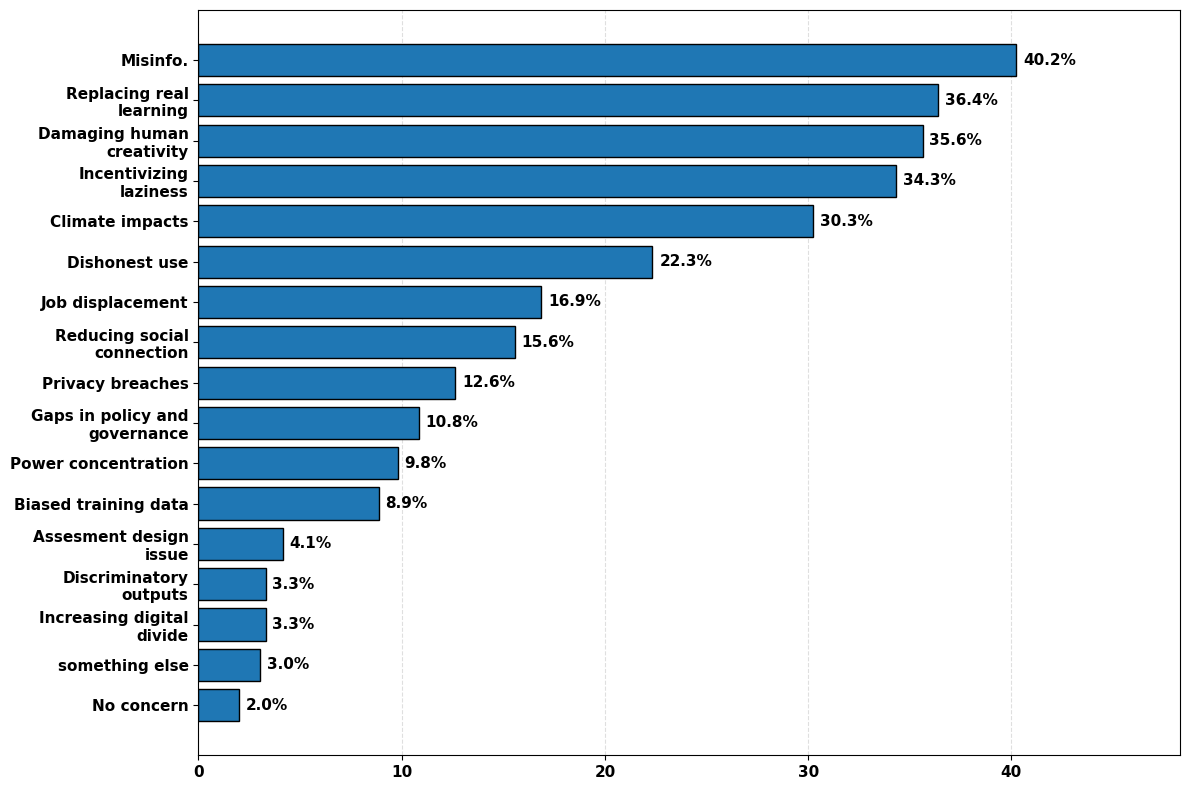

No concern                        1.98
something else                    3.02
Increasing digital divide         3.30
Discriminatory outputs            3.30
Assesment design issue            4.15
Biased training data              8.86
Power concentration               9.80
Gaps in policy and governance    10.84
Privacy breaches                 12.63
Reducing social connection       15.55
Job displacement                 16.87
Dishonest use                    22.34
Climate impacts                  30.25
Incentivizing laziness           34.31
Damaging human creativity        35.63
Replacing real learning          36.38
Misinfo.                         40.25
dtype: float64


In [457]:
n_students_answered_25 = (answered_q13_25 & student_mask_25).sum()

plot_distribution(
    counts=student_concern_25,
    denominator=n_students_answered_25,
    title="GenAI Concerns — Students (2025)",
    figsize=(12, 8),
    title_fontsize=16,
    label_fontsize=13,
    tick_fontsize=11,
    value_fontsize=11
)

In [406]:
print(student_concern_25.sort_values(ascending=False).head(3) / n_students_answered_25 * 100)
print(student_concern_26.sort_values(ascending=False).head(3) / n_students_answered * 100)


Misinfo.                     40.245052
Replacing real learning      36.380773
Damaging human creativity    35.626767
dtype: float64
Climate impacts              38.651994
Replacing real learning      36.313618
Damaging human creativity    36.313618
dtype: float64


<h4>Concerns: faculty 2025</h4>

In [459]:
faculty_concern_25 = df_25.loc[role_25 == 2, concern_cols_25].apply(pd.to_numeric, errors = 'coerce').eq(1).sum()

In [460]:
print(faculty_concern_25)

What are your most important concerns related to GenAI? Select up to 3 options below.      3
Unnamed: 144                                                                             127
Unnamed: 145                                                                              75
Unnamed: 146                                                                              32
Unnamed: 147                                                                              89
Unnamed: 148                                                                              46
Unnamed: 149                                                                              30
Unnamed: 150                                                                              14
Unnamed: 151                                                                              39
Unnamed: 152                                                                              18
Unnamed: 153                                                          

In [461]:
faculty_concern_25.index = [
    concern_mapping_25[df_25.columns.get_loc(col)]
    for col in concern_cols_25
]

In [462]:
count = 0

for idx, value in enumerate(df_25['Unnamed: 159']):
    if pd.notna(value) and str(value).strip() not in ('', '0'):
        if role_25.iloc[idx] == 2:
            count += 1

print(count)
        

11


In [464]:
faculty_concern_25['something else'] = count

In [465]:
print(faculty_concern_25.sort_values())

No concern                         3
something else                    11
Assesment design issue            12
Increasing digital divide         14
Discriminatory outputs            18
Gaps in policy and governance     27
Power concentration               30
Privacy breaches                  32
Biased training data              39
Job displacement                  46
Incentivizing laziness            47
Reducing social connection        52
Climate impacts                   75
Damaging human creativity         88
Dishonest use                     89
Replacing real learning          127
Misinfo.                         127
dtype: int64


In [466]:
# 4. Count respondents who answered at least one option
# Each respondent is counted only once, even if they chose multiple options
answered_q13 = regular_selected.any(axis=1) | selected_other

print("\n=== Q13 response counts ===")
print("Total respondents:", len(df_25))
print("Respondents who answered:", answered_q13.sum())
print("Respondents who did not answer:", (~answered_q13).sum())

# 5. Count faculty responses (role == 2)
faculty_mask = role_25 == 2

print("\n=== Faculty Q13 response counts ===")
print("Total faculty:", faculty_mask.sum())
print("Faculty who answered:", (answered_q13 & faculty_mask).sum())
print("Faculty who did not answer:", ((~answered_q13) & faculty_mask).sum())

# 6. Count each concern among faculty
faculty_concern_25 = regular_selected.loc[faculty_mask].sum()
faculty_concern_25["something else"] = selected_other.loc[faculty_mask].sum()

print("\n=== faculty concern selections ===")
print(faculty_concern_25.sort_values(ascending=False))


=== Q13 response counts ===
Total respondents: 1345
Respondents who answered: 1345
Respondents who did not answer: 0

=== Faculty Q13 response counts ===
Total faculty: 284
Faculty who answered: 284
Faculty who did not answer: 0

=== faculty concern selections ===
Misinfo.                         127
Replacing real learning          127
Dishonest use                     89
Damaging human creativity         88
Climate impacts                   75
Reducing social connection        52
Incentivizing laziness            47
Job displacement                  46
Biased training data              39
Privacy breaches                  32
Power concentration               30
Gaps in policy and governance     27
Discriminatory outputs            18
Increasing digital divide         14
Assesment design issue            12
something else                    11
No concern                         3
dtype: int64


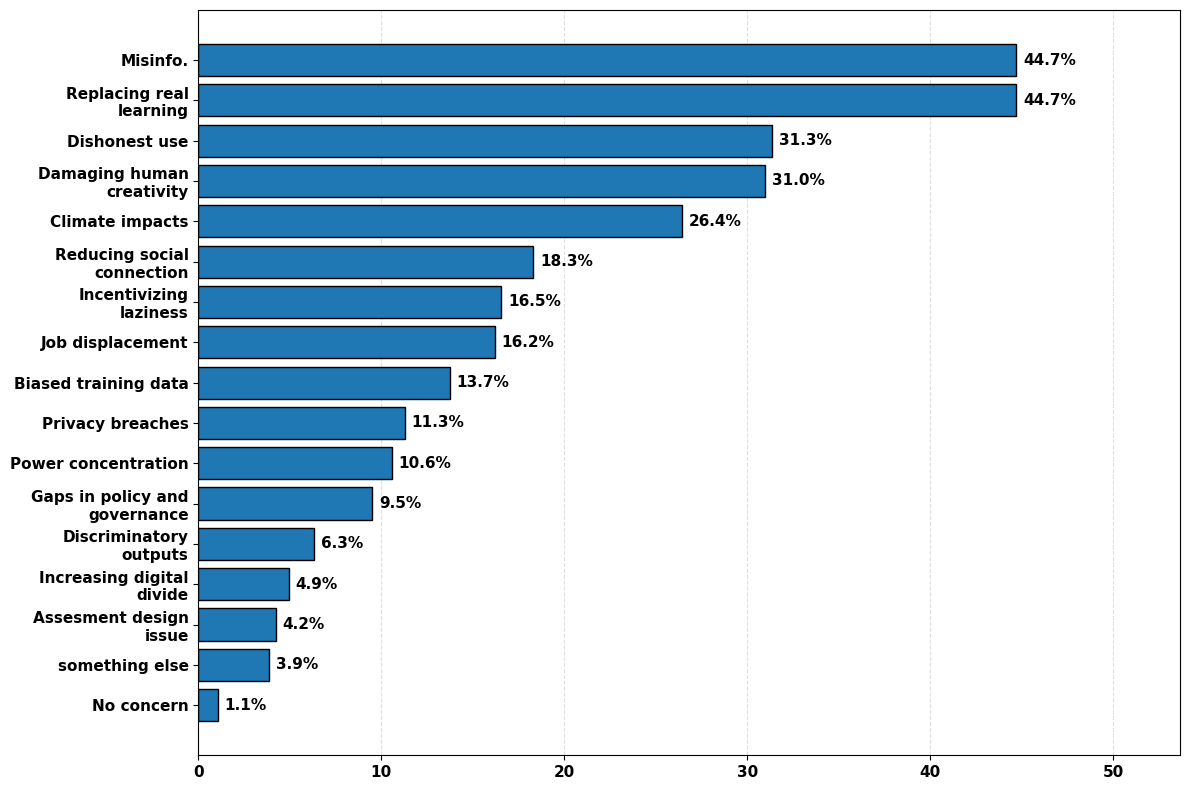

No concern                        1.06
something else                    3.87
Assesment design issue            4.23
Increasing digital divide         4.93
Discriminatory outputs            6.34
Gaps in policy and governance     9.51
Power concentration              10.56
Privacy breaches                 11.27
Biased training data             13.73
Job displacement                 16.20
Incentivizing laziness           16.55
Reducing social connection       18.31
Climate impacts                  26.41
Damaging human creativity        30.99
Dishonest use                    31.34
Replacing real learning          44.72
Misinfo.                         44.72
dtype: float64


In [469]:
n_faculty_answered_25 = (answered_q13 & faculty_mask).sum()

plot_distribution(
    counts=faculty_concern_25,
    denominator=n_faculty_answered_25,
    title="GenAI Concerns — Faculty (2025)",
    figsize=(12, 8),
    title_fontsize=16,
    label_fontsize=13,
    tick_fontsize=11,
    value_fontsize=11
)

In [470]:
print(faculty_concern_25.sort_values(ascending=False).head(3) / n_faculty_answered_25 * 100)
print(faculty_concern_26.sort_values(ascending=False).head(3) / n_faculty_answered * 100)


Misinfo.                   44.718310
Replacing real learning    44.718310
Dishonest use              31.338028
dtype: float64
Replacing real learning    44.366197
Climate impacts            34.154930
Misinfo.                   34.154930
dtype: float64


## Motivations

In [725]:
motivation_cols_26 = df_26.columns[122:138]

In [726]:
motivation_mapping_26 = {
    122: 'Being too overwhelmed',
    123: 'Not seeing value in assigned work',
    124: 'Not seeing value in work manually',
    125: 'Earning good grades',
    126: 'Earning good prof. evaluations',
    127: 'Time for personal life',
    128: 'Reducing time on low-priority tasks',
    129: 'Improving creativity',
    130: 'Quality of work',
    131: 'Depth of knowledge',
    132: 'Staying updated',
    133: 'Curisity for tech',
    134: 'Feeling presure',
    135: 'Enhancing teaching',
    136: 'Support students',
    137: 'Something else'
}
    

In [727]:
motivation_counts_26 = (
    df_26[motivation_cols_26].apply(pd.to_numeric, errors='coerce').eq(1).sum()
)

In [571]:
print(motivation_counts_26)

[Q10] What are your most important motivations for using LLM-powered chatbots or agents for your classes research and/or any other professional efforts? Select up to 3 options below.    219
Unnamed: 123                                                                                                                                                                               50
Unnamed: 124                                                                                                                                                                                6
Unnamed: 125                                                                                                                                                                              194
Unnamed: 126                                                                                                                                                                                6
Unnamed: 127                                      

In [572]:
student_motivation_26 = df_26.loc[role_26 == 1, motivation_cols_26].apply(pd.to_numeric, errors = 'coerce').eq(1).sum()

In [573]:
student_motivation_26.index = [
    motivation_mapping_26[df_26.columns.get_loc(col)]
    for col in motivation_cols_26
]

In [574]:
print(student_motivation_26)

Being too overwhelmed                  177
Not seeing value in assigned work       50
Not seeing value in work manually        0
Earning good grades                    194
Earning good prof. evaluations           0
Time for personal life                 129
Reducing time on low-priority tasks    243
Improving creativity                    16
Quality of work                        176
Depth of knowledge                     293
Staying updated                        103
Curisity for tech                       81
Feeling presure                        102
Enhancing teaching                       0
Support students                         0
Something else                           0
dtype: int64


In [576]:
print(student_motivation_26)

Being too overwhelmed                  177
Not seeing value in assigned work       50
Not seeing value in work manually        0
Earning good grades                    194
Earning good prof. evaluations           0
Time for personal life                 129
Reducing time on low-priority tasks    243
Improving creativity                    16
Quality of work                        176
Depth of knowledge                     293
Staying updated                        103
Curisity for tech                       81
Feeling presure                        102
Enhancing teaching                       0
Support students                         0
Something else                           0
dtype: int64


In [577]:
count = 0

for idx, value in enumerate(df_26['Unnamed: 137']):
    if pd.notna(value) and str(value).strip() not in ('', '0'):
        if role_26.iloc[idx] == 1:
            count += 1
            print(value)

print(count)
        

[Something else] N/A
[Something else] Only being required to
[Something else] I donât use LLMs
[Something else] Using AI either because it is required for coursework, or to help myself learn the basics of a new skill so that I can learn to do it in my own.
[Something else] Tech problems I cannot solve myself or with help of IT/CompSci friends. Also converting things / merging things into one PDF cause for some reason itâs not free with any other software. 
[Something else] I don't do it. If I don't have the skills to be a professional, why would anybody hire a mines graduate, instead of somebody who just knows how to use AI?
[Something else] None of the above
[Something else] I do not use them.
[Something else] Creating practice problems for better understanding and
[Something else] I don't have any motivation to use LLMs outside of seeding initial coding projects
[Something else] Learning what will be useful in my job. Example: attending webinar about orchestration of AI agents fo

In [578]:
other_text = (
    df_26['Unnamed: 137']
    .astype("object")
    .str.strip()
)

In [579]:
print(df_26['Unnamed: 137'].dtype)

object


In [580]:
print(df_26['Unnamed: 137'].value_counts())

Unnamed: 137
0                                                                                                                                                                                                         808
[Something else] N/A                                                                                                                                                                                        3
[Something else] Rather leading question; I do not use LLM-powered chatbots or agents for classes, research, or any other professional efforts.                                                             1
[Something else] I do not use chatbots.                                                                                                                                                                     1
[Something else] can be efficient when pressed for time                                                                                                            

In [581]:
student_motivation_26['Something else'] = count

In [582]:
print(student_motivation_26.sort_values())

Not seeing value in work manually        0
Earning good prof. evaluations           0
Enhancing teaching                       0
Support students                         0
Improving creativity                    16
Not seeing value in assigned work       50
Something else                          76
Curisity for tech                       81
Feeling presure                        102
Staying updated                        103
Time for personal life                 129
Quality of work                        176
Being too overwhelmed                  177
Earning good grades                    194
Reducing time on low-priority tasks    243
Depth of knowledge                     293
dtype: int64


In [583]:
## Counting number of respondents

In [584]:
motivation_data_26 = df_26[motivation_cols_26].copy()
motivation_data_26.columns = [
    motivation_mapping_26[pos] for pos in range(122, 138)
]

In [585]:
regular_cols = [
    col for col in motivation_data_26.columns
    if col != "Something else"
]

In [586]:
regular_selected = (
    motivation_data_26[regular_cols]
    .apply(pd.to_numeric, errors="coerce")
    .eq(1)
)

motivation_counts_26 = regular_selected.sum()

In [587]:
print(motivation_counts_26)

Being too overwhelmed                  219
Not seeing value in assigned work       50
Not seeing value in work manually        6
Earning good grades                    194
Earning good prof. evaluations           6
Time for personal life                 146
Reducing time on low-priority tasks    360
Improving creativity                    41
Quality of work                        278
Depth of knowledge                     360
Staying updated                        174
Curisity for tech                      167
Feeling presure                        132
Enhancing teaching                      21
Support students                        31
dtype: int64


In [588]:
# 3. Count "something else" only when actual text is provided
other_text = (
    motivation_data_26["Something else"]
    .astype("object")
    .str.strip()
)

selected_other = (
    other_text.notna()
    & other_text.ne("")
    & other_text.ne("0")
)

motivation_counts_26["Something else"] = selected_other.sum()
print(motivation_counts_26["Something else"])

96


In [589]:
# 4. Count respondents who answered at least one option
# Each respondent is counted only once, even if they chose multiple options
answered_q10 = regular_selected.any(axis=1) | selected_other

print("\n=== Q10 response counts ===")
print("Total respondents:", len(df_26))
print("Respondents who answered:", answered_q10.sum())
print("Respondents who did not answer:", (~answered_q10).sum())

# 5. Count student responses (role == 1)
student_mask = role_26 == 1

print("\n=== Student Q10 response counts ===")
print("Total students:", student_mask.sum())
print("Students who answered:", (answered_q10 & student_mask).sum())
print("Students who did not answer:", ((~answered_q10) & student_mask).sum())

# 6. Count each motivation among students
student_motivation_26 = regular_selected.loc[student_mask].sum()
student_motivation_26["Something else"] = selected_other.loc[student_mask].sum()

print("\n=== Student motivation selections ===")
print(student_motivation_26.sort_values(ascending=False))


=== Q10 response counts ===
Total respondents: 1008
Respondents who answered: 904
Respondents who did not answer: 104

=== Student Q10 response counts ===
Total students: 727
Students who answered: 655
Students who did not answer: 72

=== Student motivation selections ===
Depth of knowledge                     293
Reducing time on low-priority tasks    243
Earning good grades                    194
Being too overwhelmed                  177
Quality of work                        176
Time for personal life                 129
Staying updated                        103
Feeling presure                        102
Curisity for tech                       81
Something else                          76
Not seeing value in assigned work       50
Improving creativity                    16
Not seeing value in work manually        0
Earning good prof. evaluations           0
Enhancing teaching                       0
Support students                         0
dtype: int64


In [590]:
unanswered_indices = df_26.index[~answered_q10]

display(
    df_26.loc[unanswered_indices, motivation_cols_26]
)

,[Q10] What are your most important motivations for using LLM-powered chatbots or agents for your classes research and/or any other professional efforts? Select up to 3 options below.,Unnamed: 123,Unnamed: 124,Unnamed: 125,Unnamed: 126,Unnamed: 127,Unnamed: 128,Unnamed: 129,Unnamed: 130,Unnamed: 131,Unnamed: 132,Unnamed: 133,Unnamed: 134,Unnamed: 135,Unnamed: 136,Unnamed: 137
7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
22,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
26,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
31,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
32,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
956,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
969,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
973,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
974,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [591]:
unanswered_ids = df_26.loc[~answered_q10, 'Response ID']

print(unanswered_ids.to_list())

[236420383.0, 236420481.0, 236420492.0, 236420528.0, 236420544.0, 236420611.0, 236420887.0, 236421451.0, 236421938.0, 236421990.0, 236422051.0, 236422309.0, 236422445.0, 236422659.0, 236422893.0, 236422906.0, 236423270.0, 236424299.0, 236424516.0, 236424519.0, 236425793.0, 236426792.0, 236427457.0, 236427645.0, 236427872.0, 236428482.0, 236429387.0, 236429590.0, 236429917.0, 236430198.0, 236430254.0, 236430549.0, 236432334.0, 236433377.0, 236433640.0, 236434667.0, 236435515.0, 236436511.0, 236436621.0, 236437557.0, 236438563.0, 236439232.0, 236439304.0, 236443750.0, 236445136.0, 236448934.0, 236449481.0, 236451257.0, 236452332.0, 236454416.0, 236455476.0, 236455566.0, 236459766.0, 236460726.0, 236462843.0, 236465381.0, 236469264.0, 236475457.0, 236476546.0, 236476873.0, 236477579.0, 236480053.0, 236499969.0, 236514762.0, 236521408.0, 236529005.0, 236534206.0, 236580876.0, 236603766.0, 236653822.0, 236834357.0, 237002827.0, 237018684.0, 237103546.0, 237288063.0, 237331219.0, 237334585.0

In [594]:
## Participants who never or use LLM for personal life will not see this questions

In [612]:
student_usage_26.value_counts()

[Q5] LLM-powered chatbotsÂ accessed through a browser or app (e.g. ChatGPT.com Claude.ai Gemini.google.com)
4    248
5    209
3    131
1     69
2     56
6     14
Name: count, dtype: int64

In [619]:
var_coding_agent_26 = "[Q5] AI coding agentsÂ\xa0designed specifically to write modify and execute code (e.g. Claude Code Cursor Codex Antigravity Pi)"

In [621]:
student_coding_agent_26 = df_26.loc[role_26 == 1, var_coding_agent_26]

print(student_coding_agent_26.value_counts())

[Q5] AI coding agentsÂ designed specifically to write modify and execute code (e.g. Claude Code Cursor Codex Antigravity Pi)
1    339
2    132
3    110
4     90
5     41
6     15
Name: count, dtype: int64


In [623]:
usage = pd.to_numeric(df_26[usage_var_26], errors="coerce")
coding_agent = pd.to_numeric(df_26[var_coding_agent_26], errors="coerce")

student_mask = role_26 == 1

eligible_mask = (
    student_mask
    & (
        usage.between(2, 5)
        | coding_agent.between(2, 5)
    )
)

print("Total students:", student_mask.sum())
print("Students eligible for Q10:", eligible_mask.sum())
print("Students not eligible for Q10:", (student_mask & ~eligible_mask).sum())

print("\nQ10 response status:")
print("Answered:", (eligible_mask & answered_q10).sum())
print("Not answered:", (eligible_mask & ~answered_q10).sum())

Total students: 727
Students eligible for Q10: 655
Students not eligible for Q10: 72

Q10 response status:
Answered: 655
Not answered: 0


In [599]:
### Keep only necessary options for student

# student_motivation_26 = student_motivation_26.drop([
#     'Enhancing teaching',
#     'Support students',
#     'Earning good prof. evaluations'
# ]) ## these three options are only for faculty

# print(student_motivation_26)

In [600]:
print(student_motivation_26)

Being too overwhelmed                  177
Not seeing value in assigned work       50
Not seeing value in work manually        0
Earning good grades                    194
Time for personal life                 129
Reducing time on low-priority tasks    243
Improving creativity                    16
Quality of work                        176
Depth of knowledge                     293
Staying updated                        103
Curisity for tech                       81
Feeling presure                        102
Something else                          76
dtype: int64


655


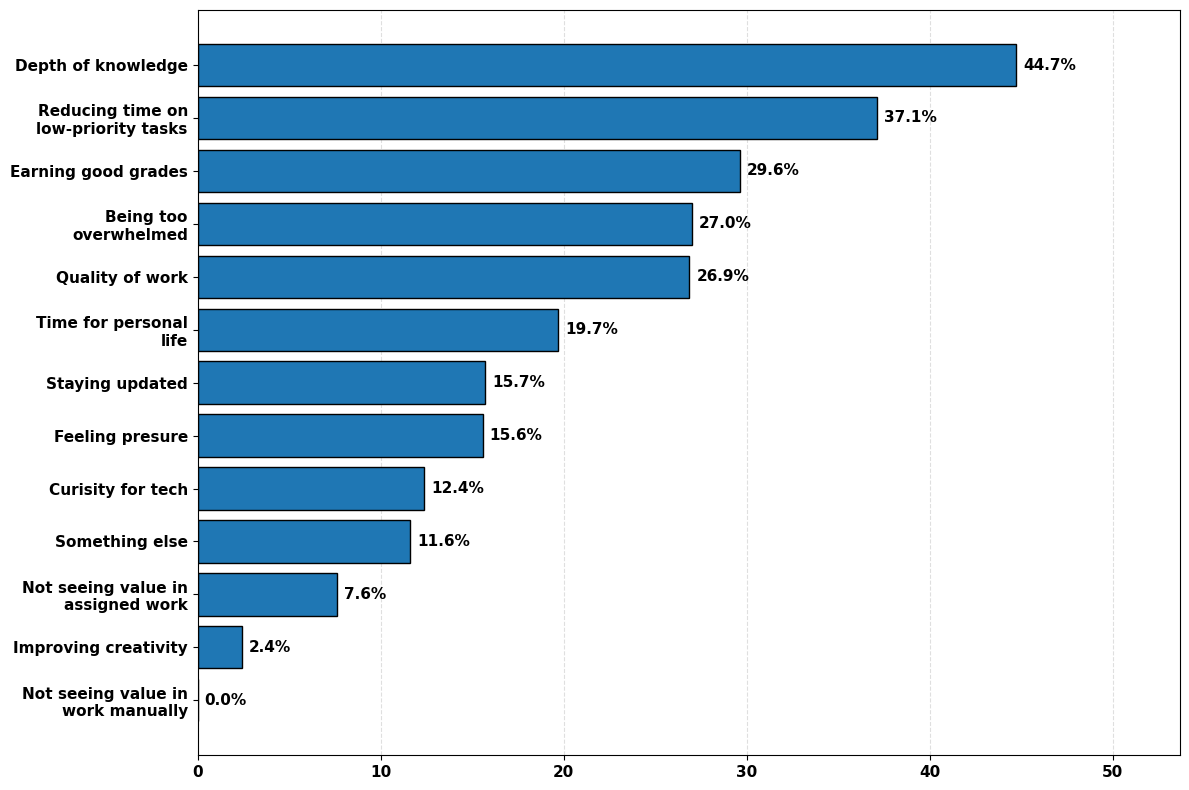

Not seeing value in work manually       0.00
Improving creativity                    2.44
Not seeing value in assigned work       7.63
Something else                         11.60
Curisity for tech                      12.37
Feeling presure                        15.57
Staying updated                        15.73
Time for personal life                 19.69
Quality of work                        26.87
Being too overwhelmed                  27.02
Earning good grades                    29.62
Reducing time on low-priority tasks    37.10
Depth of knowledge                     44.73
dtype: float64


In [605]:
n_students_answered_26 = (answered_q10 & student_mask).sum()
print(n_students_answered_26)

plot_distribution(
    counts=student_motivation_26,
    denominator=n_students_answered_26,
    title="GenAI Motivation — Students (2026)",
    figsize=(12, 8),
    title_fontsize=16,
    label_fontsize=13,
    tick_fontsize=11,
    value_fontsize=11
)

In [624]:
## Faculty Motivation: 2026

In [625]:
faculty_motivation_26 = df_26.loc[role_26 == 2, motivation_cols_26].apply(pd.to_numeric, errors = 'coerce').eq(1).sum()

In [626]:
faculty_motivation_26.index = [
    motivation_mapping_26[df_26.columns.get_loc(col)]
    for col in motivation_cols_26
]

In [627]:
print(faculty_motivation_26)

Being too overwhelmed                   42
Not seeing value in assigned work        0
Not seeing value in work manually        6
Earning good grades                      0
Earning good prof. evaluations           6
Time for personal life                  17
Reducing time on low-priority tasks    117
Improving creativity                    25
Quality of work                        102
Depth of knowledge                      67
Staying updated                         71
Curisity for tech                       86
Feeling presure                         30
Enhancing teaching                      21
Support students                        31
Something else                           0
dtype: int64


In [628]:
count = 0

for idx, value in enumerate(df_26['Unnamed: 137']):
    if pd.notna(value) and str(value).strip() not in ('', '0'):
        if role_26.iloc[idx] == 2:
            count += 1
            print(value)

print(count)

[Something else] Summarization
[Something else] Expected to use it by supervisors
[Something else] I often use it for solving computer issues 
[Something else] it helps me verify complex topics after I spend time researching. 
[Something else] It is a requirement to use for my position, which I do not like.
[Something else] A large part of my work is reading building code and analyzing plans - I use AI as a more anvanced Control-F function to find relavent snippets; To speed up necesarry manual tasks. 
[Something else] I don't use them
[Something else] Helping me to make sure emails I write have the correct tone, depending on the recipient. I always write my own emails, but will ask AI for suggestions to soften the tone if I feel it might be too direct.
[Something else] Enhances skills and shortens time investment in some tasks. I like to use AI to generate slides for presentations for example. It is quicker than searching for images, tailors it to my content and provides visuals that 

In [629]:
faculty_motivation_26['Something else'] = count

In [630]:
# 4. Count respondents who answered at least one option
# Each respondent is counted only once, even if they chose multiple options
answered_q10 = regular_selected.any(axis=1) | selected_other

print("\n=== Q10 response counts ===")
print("Total respondents:", len(df_26))
print("Respondents who answered:", answered_q10.sum())
print("Respondents who did not answer:", (~answered_q10).sum())

# 5. Count student responses (role == 1)
faculty_mask = role_26 == 2

print("\n=== faculty Q10 response counts ===")
print("Total faculty:", faculty_mask.sum())
print("faculty who answered:", (answered_q10 & faculty_mask).sum())
print("faculty who did not answer:", ((~answered_q10) & faculty_mask).sum())

# 6. Count each motivation among students
faculty_motivation_26 = regular_selected.loc[faculty_mask].sum()
faculty_motivation_26["Something else"] = selected_other.loc[faculty_mask].sum()

print("\n=== faculty motivation selections ===")
print(faculty_motivation_26.sort_values(ascending=False))


=== Q10 response counts ===
Total respondents: 1008
Respondents who answered: 904
Respondents who did not answer: 104

=== faculty Q10 response counts ===
Total faculty: 281
faculty who answered: 249
faculty who did not answer: 32

=== faculty motivation selections ===
Reducing time on low-priority tasks    117
Quality of work                        102
Curisity for tech                       86
Staying updated                         71
Depth of knowledge                      67
Being too overwhelmed                   42
Support students                        31
Feeling presure                         30
Improving creativity                    25
Enhancing teaching                      21
Something else                          20
Time for personal life                  17
Not seeing value in work manually        6
Earning good prof. evaluations           6
Not seeing value in assigned work        0
Earning good grades                      0
dtype: int64


In [848]:
### Keep only necessary options for faculty

# faculty_motivation_26 = faculty_motivation_26.drop([
#     'Earning good grades'
# ]) ## this option are only for student

# print(faculty_motivation_26)

249


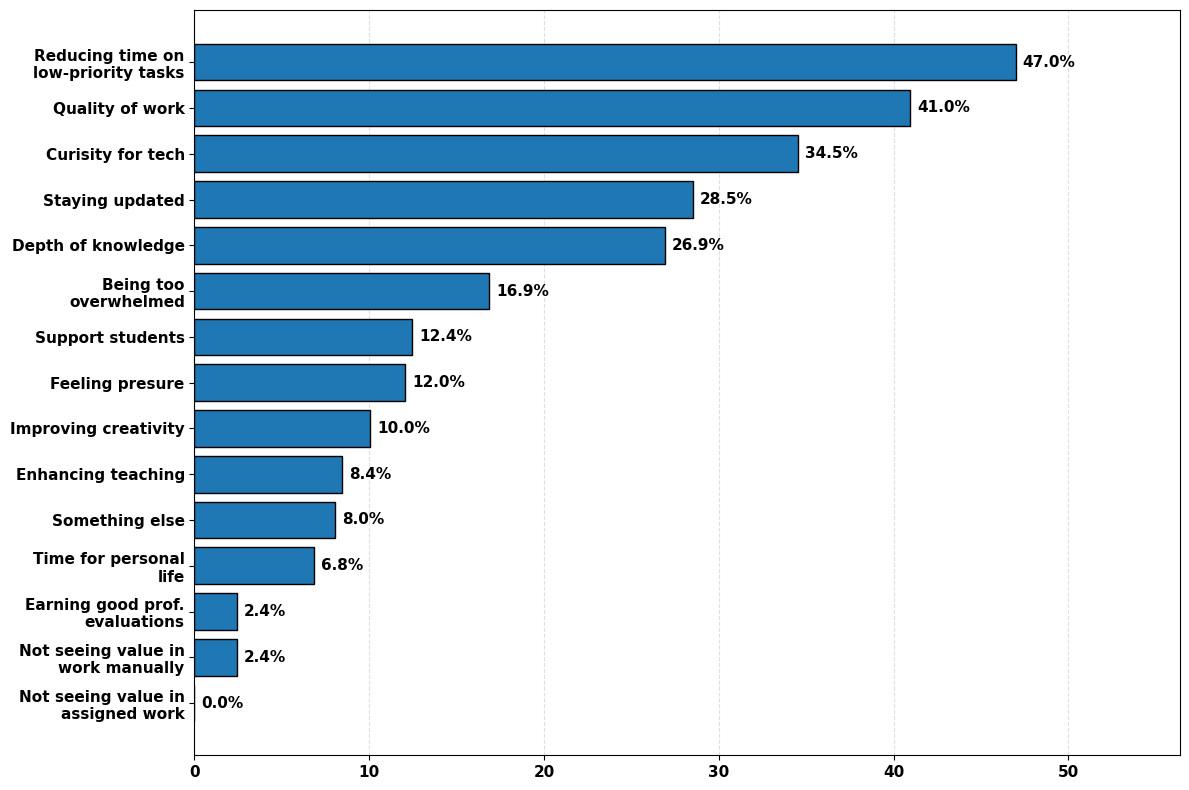

Not seeing value in assigned work       0.00
Not seeing value in work manually       2.41
Earning good prof. evaluations          2.41
Time for personal life                  6.83
Something else                          8.03
Enhancing teaching                      8.43
Improving creativity                   10.04
Feeling presure                        12.05
Support students                       12.45
Being too overwhelmed                  16.87
Depth of knowledge                     26.91
Staying updated                        28.51
Curisity for tech                      34.54
Quality of work                        40.96
Reducing time on low-priority tasks    46.99
dtype: float64


In [632]:
n_faculty_answered_26 = (answered_q10 & faculty_mask).sum()
print(n_faculty_answered_26)

plot_distribution(
    counts=faculty_motivation_26,
    denominator=n_faculty_answered_26,
    title="GenAI Motivation — Students (2026)",
    figsize=(12, 8),
    title_fontsize=16,
    label_fontsize=13,
    tick_fontsize=11,
    value_fontsize=11
)

In [633]:
## Motivation: 2025

In [826]:
print(motivation_mapping_26)

{122: 'Being too overwhelmed', 123: 'Not seeing value in assigned work', 124: 'Not seeing value in work manually', 125: 'Earning good grades', 126: 'Earning good prof. evaluations', 127: 'Time for personal life', 128: 'Reducing time on low-priority tasks', 129: 'Improving creativity', 130: 'Quality of work', 131: 'Depth of knowledge', 132: 'Staying updated', 133: 'Curisity for tech', 134: 'Feeling presure', 135: 'Enhancing teaching', 136: 'Support students', 137: 'Something else'}


In [827]:
motivation_cols_25 = df_25.columns[103:119]

In [828]:
motivation_mapping_25 = {
    103: 'Being too overwhelmed',
    104: 'Not seeing value in assigned work',
    105: 'Not seeing value in work manually',
    106: 'Earning good grade',
    107: 'Earning good prof. evaluations',
    108: 'Time for personal life',
    109: 'Reducing time on low-priority tasks',
    110: 'Improving creativity',
    111: 'Quality of work',
    112: 'Depth of knowledge',
    113: 'Staying updated',
    114: 'Curisity for tech',
    115: 'Feeling presure',
    116: 'Enhancing teaching',
    117: 'Support students',
    118: 'Something else'
}

In [829]:
motivation_counts_25 = (
    df_25[motivation_cols_25].apply(pd.to_numeric, errors='coerce').eq(1).sum()
)

In [830]:
motivation_counts_25

What are your most important motivations for using LLM-powered chatbots for your classes, research, and/or any other professional efforts? Select up to 3 options below.    246
Unnamed: 104                                                                                                                                                                 76
Unnamed: 105                                                                                                                                                                  6
Unnamed: 106                                                                                                                                                                225
Unnamed: 107                                                                                                                                                                  3
Unnamed: 108                                                                                                            

In [831]:
student_motivation_25 = df_25.loc[role_25 == 1, motivation_cols_25].apply(pd.to_numeric, errors = 'coerce').eq(1).sum()

In [832]:
student_motivation_25.index = [
    motivation_mapping_25[df_25.columns.get_loc(col)]
    for col in motivation_cols_25
]

In [833]:
student_motivation_25

Being too overwhelmed                  227
Not seeing value in assigned work       76
Not seeing value in work manually        0
Earning good grade                     225
Earning good prof. evaluations           0
Time for personal life                 168
Reducing time on low-priority tasks    391
Improving creativity                    46
Quality of work                        256
Depth of knowledge                     483
Staying updated                        103
Curisity for tech                      161
Feeling presure                         70
Enhancing teaching                       0
Support students                         0
Something else                           0
dtype: int64

In [834]:
count = 0

for idx, value in enumerate(df_25['Unnamed: 118']):
    if pd.notna(value) and str(value).strip() not in ('', '0'):
        if role_25.iloc[idx] == 1:
            count += 1
            print(value)

print(count)

[Something else] The chatbot is simply better than me in most topics. I can turn in better quality work if I use the LLM
[Something else] Being forced to for a grade by my classes
[Something else] Creating lists of questions based off of my professors academic profiles and the research I am doing to help better understand what is expected of me.
[Something else] it's required by an assignment
[Something else] Its required for some classes like global studies to use a chatbot
[Something else] Required to for assignment
[Something else] In some of my classes we have homework that has a question that makes us use AI.
[Something else] checking my answers on homework problems to make sure I have done them correctly
[Something else] Needing to understand how to do a problem or why I got it wrong
[Something else] Required to use it for class assignments
[Something else] Some professors require usage for assignments
[Something else] Requirement by classes
[Something else] N/A
[Something else]

In [835]:
other_text = (
    df_25['Unnamed: 118']
    .astype("object")
    .str.strip()
)

In [836]:
student_motivation_25['Something else'] = count

In [838]:
print(student_motivation_25.sort_values())

Not seeing value in work manually        0
Earning good prof. evaluations           0
Enhancing teaching                       0
Support students                         0
Something else                          38
Improving creativity                    46
Feeling presure                         70
Not seeing value in assigned work       76
Staying updated                        103
Curisity for tech                      161
Time for personal life                 168
Earning good grade                     225
Being too overwhelmed                  227
Quality of work                        256
Reducing time on low-priority tasks    391
Depth of knowledge                     483
dtype: int64


In [839]:
## Counting number of respondent

In [840]:
motivation_data_25 = df_25[motivation_cols_25].copy()
motivation_data_25.columns = [
    motivation_mapping_25[pos] for pos in range(103, 119)
]

In [841]:
regular_cols = [
    col for col in motivation_data_25.columns
    if col != "Something else"
]

regular_selected = (
    motivation_data_25[regular_cols]
    .apply(pd.to_numeric, errors="coerce")
    .eq(1)
)

motivation_counts_25 = regular_selected.sum()
print(motivation_counts_25)


Being too overwhelmed                  246
Not seeing value in assigned work       76
Not seeing value in work manually        6
Earning good grade                     225
Earning good prof. evaluations           3
Time for personal life                 178
Reducing time on low-priority tasks    499
Improving creativity                    75
Quality of work                        339
Depth of knowledge                     523
Staying updated                        189
Curisity for tech                      261
Feeling presure                        105
Enhancing teaching                      23
Support students                        42
dtype: int64


In [842]:
# 3. Count "something else" only when actual text is provided
other_text = (
    motivation_data_25["Something else"]
    .astype("object")
    .str.strip()
)

selected_other = (
    other_text.notna()
    & other_text.ne("")
    & other_text.ne("0")
)

motivation_counts_25["Something else"] = selected_other.sum()
print(motivation_counts_25["Something else"])


50


In [843]:
# 4. Count respondents who answered at least one option
# Each respondent is counted only once, even if they chose multiple options
answered_q10 = regular_selected.any(axis=1) | selected_other

print("\n=== Q10 response counts ===")
print("Total respondents:", len(df_25))
print("Respondents who answered:", answered_q10.sum())
print("Respondents who did not answer:", (~answered_q10).sum())

# 5. Count student responses (role == 1)
student_mask = role_25 == 1

print("\n=== Student Q10 response counts ===")
print("Total students:", student_mask.sum())
print("Students who answered:", (answered_q10 & student_mask).sum())
print("Students who did not answer:", ((~answered_q10) & student_mask).sum())

# 6. Count each motivation among students
student_motivation_25 = regular_selected.loc[student_mask].sum()
student_motivation_25["Something else"] = selected_other.loc[student_mask].sum()

print("\n=== Student motivation selections ===")
print(student_motivation_25.sort_values(ascending=False))



=== Q10 response counts ===
Total respondents: 1345
Respondents who answered: 1080
Respondents who did not answer: 265

=== Student Q10 response counts ===
Total students: 1061
Students who answered: 858
Students who did not answer: 203

=== Student motivation selections ===
Depth of knowledge                     483
Reducing time on low-priority tasks    391
Quality of work                        256
Being too overwhelmed                  227
Earning good grade                     225
Time for personal life                 168
Curisity for tech                      161
Staying updated                        103
Not seeing value in assigned work       76
Feeling presure                         70
Improving creativity                    46
Something else                          38
Not seeing value in work manually        0
Earning good prof. evaluations           0
Enhancing teaching                       0
Support students                         0
dtype: int64


In [845]:
### Keep only necessary options for student

# student_motivation_25 = student_motivation_25.drop([
#     'Enhancing teaching',
#     'Support students',
#     'Earning good prof. evaluations'
# ]) ## these three options are only for faculty

# print(student_motivation_25)

858


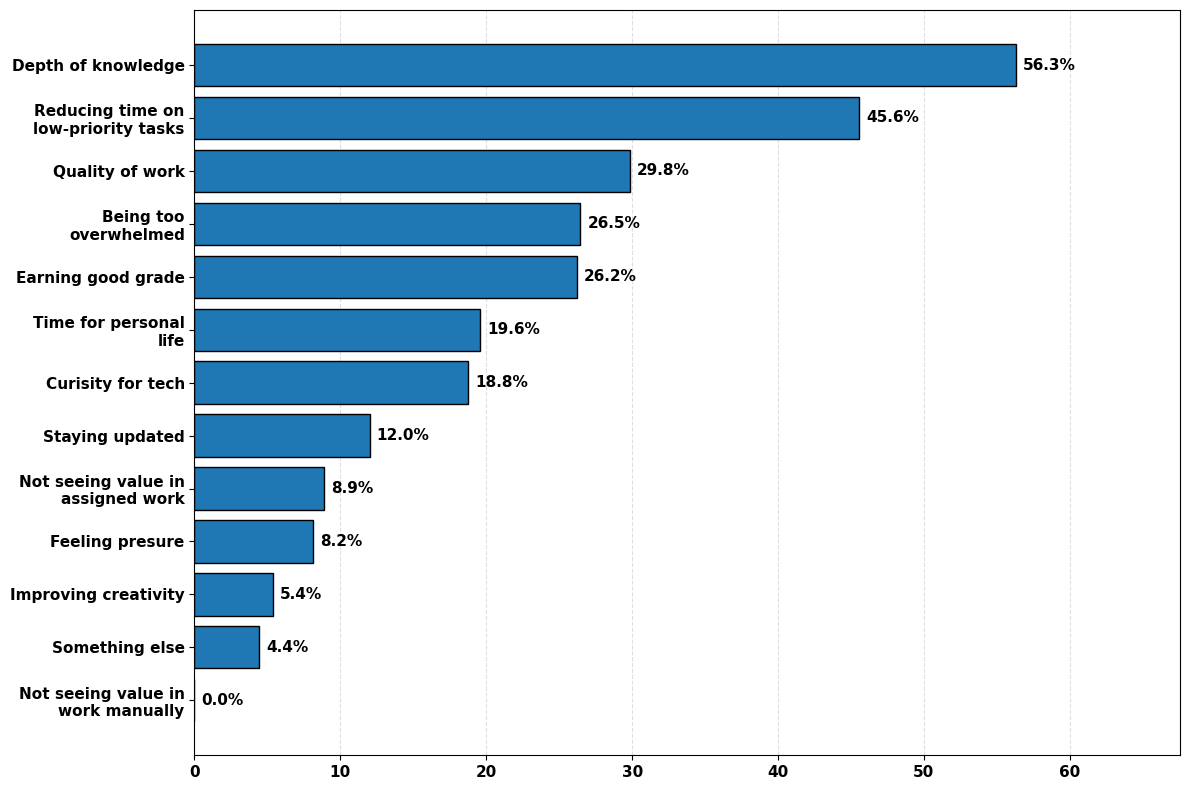

Not seeing value in work manually       0.00
Something else                          4.43
Improving creativity                    5.36
Feeling presure                         8.16
Not seeing value in assigned work       8.86
Staying updated                        12.00
Curisity for tech                      18.76
Time for personal life                 19.58
Earning good grade                     26.22
Being too overwhelmed                  26.46
Quality of work                        29.84
Reducing time on low-priority tasks    45.57
Depth of knowledge                     56.29
dtype: float64


In [846]:
n_students_answered_25 = (answered_q10 & student_mask).sum()
print(n_students_answered_25)

plot_distribution(
    counts=student_motivation_25,
    denominator=n_students_answered_25,
    title="GenAI Motivation — Students (2026)",
    figsize=(12, 8),
    title_fontsize=16,
    label_fontsize=13,
    tick_fontsize=11,
    value_fontsize=11
)

In [847]:
## Faculty 2025

In [854]:
faculty_motivation_25 = df_25.loc[role_25 == 2, motivation_cols_25].apply(pd.to_numeric, errors = 'coerce').eq(1).sum()

faculty_motivation_25.index = [
    motivation_mapping_25[df_25.columns.get_loc(col)]
    for col in motivation_cols_25
]
print(faculty_motivation_25)


Being too overwhelmed                   19
Not seeing value in assigned work        0
Not seeing value in work manually        6
Earning good grade                       0
Earning good prof. evaluations           3
Time for personal life                  10
Reducing time on low-priority tasks    108
Improving creativity                    29
Quality of work                         83
Depth of knowledge                      40
Staying updated                         86
Curisity for tech                      100
Feeling presure                         35
Enhancing teaching                      23
Support students                        42
Something else                           0
dtype: int64


In [855]:
count = 0

for idx, value in enumerate(df_25['Unnamed: 118']):
    if pd.notna(value) and str(value).strip() not in ('', '0'):
        if role_25.iloc[idx] == 2:
            count += 1
            print(value)

print(count)


[Something else] Gathering different ideas that I may not be considering
[Something else] Getting better answers than a Google search - can have a conversation with it if the answer isn't exactly what you're looking for
[Something else] My research has focused on understanding the security impacts of LLMs and code generation models, so I am using them to understand just how bad the state of affairs is.
[Something else] Required to use it by my supervisors
[Something else] Trying to be more efficient (aka reduce time on work tasks - but not just the low-priority, non-essential ones)
[Something else] Necessary to enable SOTA performance of some computer systems.
[Something else] Writing S.M.A.R.T. goals for myself and my staff. First pass only.
[Something else] I know students are using it ..
[Something else] Complete tasks I am unable to do with my knowledge base
[Something else] Tools I use have AI built into them naturally.
[Something else] I look at it as another tool in my tool kit 

In [856]:
faculty_motivation_25['Something else'] = count


In [858]:
# 4. Count respondents who answered at least one option
# Each respondent is counted only once, even if they chose multiple options
answered_q10 = regular_selected.any(axis=1) | selected_other

print("\n=== Q10 response counts ===")
print("Total respondents:", len(df_25))
print("Respondents who answered:", answered_q10.sum())
print("Respondents who did not answer:", (~answered_q10).sum())

# 5. Count student responses (role == 1)
faculty_mask = role_25 == 2

print("\n=== faculty Q10 response counts ===")
print("Total faculty:", faculty_mask.sum())
print("faculty who answered:", (answered_q10 & faculty_mask).sum())
print("faculty who did not answer:", ((~answered_q10) & faculty_mask).sum())

# 6. Count each motivation among students
faculty_motivation_25 = regular_selected.loc[faculty_mask].sum()
faculty_motivation_25["Something else"] = selected_other.loc[faculty_mask].sum()

print("\n=== faculty motivation selections ===")
print(faculty_motivation_25.sort_values(ascending=False))



=== Q10 response counts ===
Total respondents: 1345
Respondents who answered: 1080
Respondents who did not answer: 265

=== faculty Q10 response counts ===
Total faculty: 284
faculty who answered: 222
faculty who did not answer: 62

=== faculty motivation selections ===
Reducing time on low-priority tasks    108
Curisity for tech                      100
Staying updated                         86
Quality of work                         83
Support students                        42
Depth of knowledge                      40
Feeling presure                         35
Improving creativity                    29
Enhancing teaching                      23
Being too overwhelmed                   19
Something else                          12
Time for personal life                  10
Not seeing value in work manually        6
Earning good prof. evaluations           3
Not seeing value in assigned work        0
Earning good grade                       0
dtype: int64


In [861]:
# faculty_motivation_25 = faculty_motivation_25.drop([
#     'Earning good grade'
# ]) ## this option are only for student

# print(faculty_motivation_25)



222


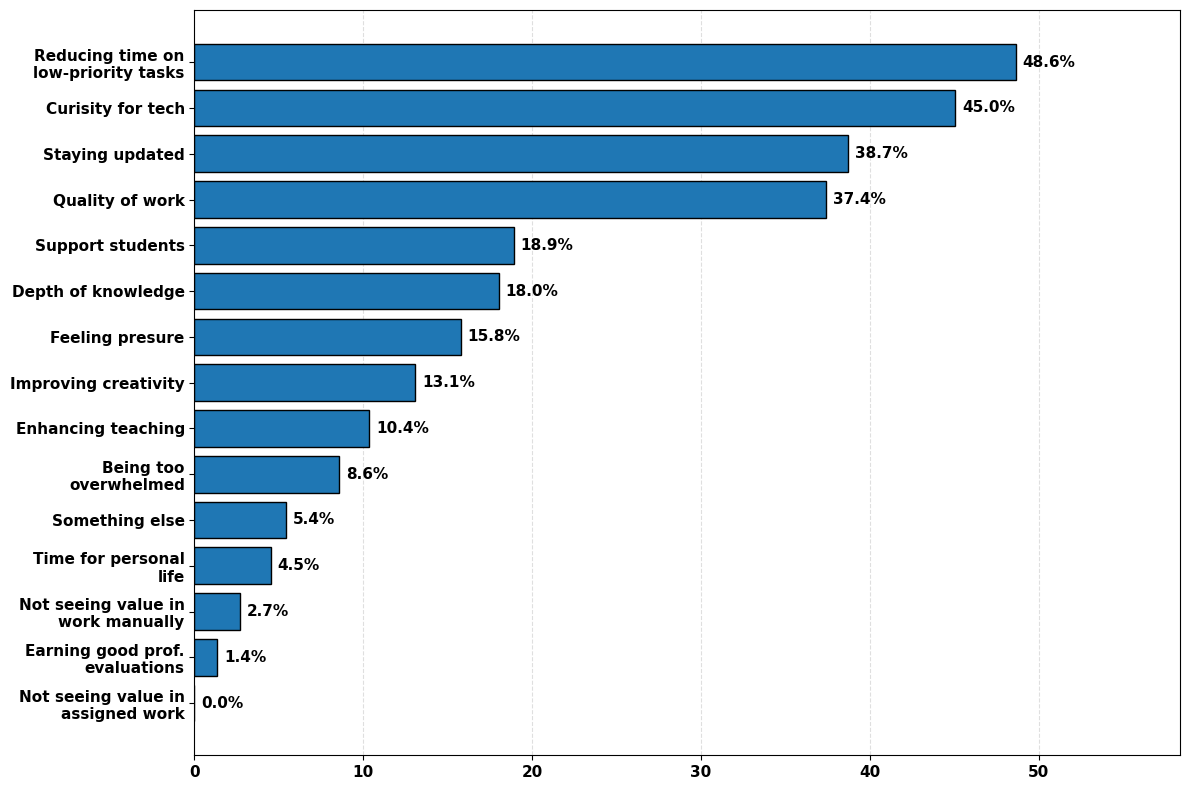

Not seeing value in assigned work       0.00
Earning good prof. evaluations          1.35
Not seeing value in work manually       2.70
Time for personal life                  4.50
Something else                          5.41
Being too overwhelmed                   8.56
Enhancing teaching                     10.36
Improving creativity                   13.06
Feeling presure                        15.77
Depth of knowledge                     18.02
Support students                       18.92
Quality of work                        37.39
Staying updated                        38.74
Curisity for tech                      45.05
Reducing time on low-priority tasks    48.65
dtype: float64


In [862]:
n_faculty_answered_25 = (answered_q10 & faculty_mask).sum()
print(n_faculty_answered_25)

plot_distribution(
    counts=faculty_motivation_25,
    denominator=n_faculty_answered_25,
    title="GenAI Motivation — Faculty (2025)",
    figsize=(12, 8),
    title_fontsize=16,
    label_fontsize=13,
    tick_fontsize=11,
    value_fontsize=11
)

## Cheating Question

In [635]:
cheating_var_26 = "[Q52] How often do you feel that you haveÂ\xa0cheated by using GenAI this semester?Â\xa0(Reminder: There will never be academic repercussions for participating in this survey.Â\xa0Please be honest!)Â\xa0"

In [636]:
student_cheating_26 = df_26.loc[role_26 == 1, cheating_var_26]

In [639]:
print(student_cheating_26.value_counts())

[Q52] How often do you feel that you haveÂ cheated by using GenAI this semester?Â (Reminder: There will never be academic repercussions for participating in this survey.Â Please be honest!)Â 
1.0    268
3.0    179
2.0    138
4.0     60
5.0     10
Name: count, dtype: int64


In [643]:
email_var_26 = "[Q38] You may now submit this survey fully anonymouslyÂ\xa0orÂ\xa0you can provide your Mines email.Providing your Mines email will help the the scientific community to understand impactful questions about how students reported GenAI use correlates with actual academic performance. InÂ\xa0 Fall25 over 450 students opted in which is incredible for the scientific questions we hope to answer--thank you so much. If you were one of them please do share again this year! We can analyze how your responses changed in the last year and improve the granularity of our analysis.Â\xa0But this is fullyÂ\xa0optionalÂ\xa0and we genuinely appreciate your participation either way. If you wish to authorize the release of FERPA-protected records please provide your Mines email. If not click the Done button below to submit your response anonymously.AUTHORIZATION FOR RELEASE OF EDUCATION RECORDS FOR RESEARCH:Some of the individual student data the research team will access is protected as education records under the Family Educational Rights and Privacy Act (FERPA). FERPA is a federal law that gives students various rights with respect to their education records. Under FERPA you have the right to inspect and review your education records the right to request amendment of records you believe are inaccurate or misleading and the right to prevent disclosure of information from your education records without your prior consent subject to some specific exceptions.Â\xa0I hereby authorize Colorado School of Mines to disclose records of my transcript and grades (including overall GPA)Â\xa0upon request to exactly one trained PhD researcher in the research lab of Prof. C. Estelle Smith. This information will never be shared beyond that one PhD researcher and will have no academic repercussions. Even if you are a student actively or previously enrolled in Prof. Smiths or Fierros course(s) they willÂ\xa0notÂ\xa0view your survey response. Your FERPA-protected data may be released to this PhD researcher only after grades have been submitted at the end of the Fall 2026 semester.Â\xa0Provide your Mines email if you authorize the future release of your transcript and GPA:"

In [645]:
student_email_26 = df_26.loc[role_26 == 1, email_var_26]

In [647]:
print(student_email_26.isna().sum())

394


In [648]:
print(student_email_26.value_counts())

[Q38] You may now submit this survey fully anonymouslyÂ orÂ you can provide your Mines email.Providing your Mines email will help the the scientific community to understand impactful questions about how students reported GenAI use correlates with actual academic performance. InÂ  Fall25 over 450 students opted in which is incredible for the scientific questions we hope to answer--thank you so much. If you were one of them please do share again this year! We can analyze how your responses changed in the last year and improve the granularity of our analysis.Â But this is fullyÂ optionalÂ and we genuinely appreciate your participation either way. If you wish to authorize the release of FERPA-protected records please provide your Mines email. If not click the Done button below to submit your response anonymously.AUTHORIZATION FOR RELEASE OF EDUCATION RECORDS FOR RESEARCH:Some of the individual student data the research team will access is protected as education records under the Family Edu

In [651]:
import pandas as pd
import numpy as np

# Select students
student_data = df_26.loc[role_26 == 1].copy()

# Extract cheating frequency
student_data['cheating'] = pd.to_numeric(
    student_data[cheating_var_26],
    errors='coerce'
)

# Extract email column
student_data['email'] = student_data[email_var_26]

# Create binary email variable
student_data['email_given'] = (
    student_data['email'].notna()
    & student_data['email'].astype(str).str.strip().ne('')
).astype(int)

# Keep complete observations
analysis_data = student_data[
    ['cheating', 'email_given']
].dropna()

print(analysis_data['email_given'].value_counts())
print(analysis_data['cheating'].value_counts().sort_index())

email_given
0    354
1    301
Name: count, dtype: int64
cheating
1.0    268
2.0    138
3.0    179
4.0     60
5.0     10
Name: count, dtype: int64


In [652]:
from statsmodels.miscmodels.ordinal_model import OrderedModel

model = OrderedModel(
    analysis_data['cheating'],
    analysis_data[['email_given']],
    distr='logit'
)

results = model.fit(method='bfgs')

print(results.summary())

Optimization terminated successfully.
         Current function value: 1.327891
         Iterations: 18
         Function evaluations: 19
         Gradient evaluations: 19
                             OrderedModel Results                             
Dep. Variable:               cheating   Log-Likelihood:                -869.77
Model:                   OrderedModel   AIC:                             1750.
Method:            Maximum Likelihood   BIC:                             1772.
Date:                Mon, 02 Nov 2026                                         
Time:                        16:17:45                                         
No. Observations:                 655                                         
Df Residuals:                     650                                         
Df Model:                           1                                         
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------

coefficient of email_given = -0.2932

Because it is negative, providing an email address is associated with lower cheating responses.

In [653]:
# Regression coefficient
coef = results.params['email_given']

# Odds ratio
odds_ratio = np.exp(coef)

# 95% confidence interval
conf = results.conf_int().loc['email_given']
or_ci = np.exp(conf)

print(f"Odds Ratio: {odds_ratio:.3f}")
print(f"95% CI: [{or_ci.iloc[0]:.3f}, {or_ci.iloc[1]:.3f}]")
print(f"p-value: {results.pvalues['email_given']:.4f}")

Odds Ratio: 0.746
95% CI: [0.563, 0.988]
p-value: 0.0411


This means that students who provided an email address had approximately 25.4% lower odds of being in a higher cheating category, compared with students who did not provide an email address.

(1-0.746)*100=25.4\%


An ordinal logistic regression examined the association between providing an email address and self-reported cheating frequency among 655 students. Providing an email address was significantly associated with lower odds of reporting a higher cheating frequency (OR = 0.746, 95% CI [0.563, 0.988], p = .041). Specifically, students who provided an email address had approximately 25.4% lower cumulative odds of reporting a higher cheating category than those who did not provide one.

In [655]:
# Predicted probability of each cheating category
pred_data = pd.DataFrame({
    'email_given': [0, 1]
})

predicted_probs = results.model.predict(
    results.params,
    exog=pred_data
)

predicted_probs = pd.DataFrame(
    predicted_probs,
    index=['No email provided', 'Email provided'],
    columns=sorted(analysis_data['cheating'].unique())
)

print(predicted_probs.round(3))

                     1.0    2.0    3.0    4.0    5.0
No email provided  0.376  0.212  0.292  0.102  0.017
Email provided     0.447  0.209  0.251  0.079  0.013


The pattern is quite clear:
- Students who provided an email address have a higher predicted probability of being in category 1 (44.7% vs. 37.6%).
- They have lower predicted probabilities in categories 3, 4, and 5.
- Category 2 is nearly identical between the groups.
This is consistent with our negative regression coefficient.

In [721]:
def ordinal_regression(X, y, distr='logit'):
    X = X.astype(float)
    y = y.astype(int)

    model = OrderedModel(
        endog=y,
        exog=X,
        distr=distr
    )

    results = model.fit(method='bfgs')
    print(results.summary())

    return results

In [715]:
student_data_25['cheating'].value_counts()

cheating
1.0    331
3.0    295
2.0    163
4.0     54
5.0     15
Name: count, dtype: int64

In [716]:
# Select all students
student_data_25 = df_25.loc[role_25 == 1].copy()

# Extract email column at position 187
student_data_25['email'] = student_data_25.iloc[:, 187]

student_data_25['cheating'] =  pd.to_numeric(
    student_data_25.iloc[:, 102],
    errors='coerce'
)

# Create binary email variable
student_data_25['email_given'] = (
    student_data_25['email'].notna()
    & student_data_25['email'].astype('string').str.strip().ne('')
).astype(int)

# Verify
print("Total students:", len(student_data_25))
print("\nEmail classification:")
print(student_data_25['email_given'].value_counts(dropna=False))

Total students: 1061

Email classification:
email_given
0    610
1    451
Name: count, dtype: int64


In [717]:
print(analysis_data_25['cheating'].dtype)
print(analysis_data_25['cheating'].unique())

print(analysis_data_25['email_given'].dtype)
print(analysis_data_25['email_given'].unique())

float64
[2. 1. 3. 4. 5.]
int64
[0 1]


In [718]:
# Keep complete observations
analysis_data_25 = student_data_25[
    ['cheating', 'email_given']
].dropna()

print(analysis_data_25['email_given'].value_counts())
print(analysis_data_25['cheating'].value_counts().sort_index())

email_given
0    505
1    353
Name: count, dtype: int64
cheating
1.0    331
2.0    163
3.0    295
4.0     54
5.0     15
Name: count, dtype: int64


In [722]:
results_25 = ordinal_regression(
    X=analysis_data_25[['email_given']],
    y=analysis_data_25['cheating']
)

Optimization terminated successfully.
         Current function value: 1.292962
         Iterations: 17
         Function evaluations: 18
         Gradient evaluations: 18
                             OrderedModel Results                             
Dep. Variable:               cheating   Log-Likelihood:                -1109.4
Model:                   OrderedModel   AIC:                             2229.
Method:            Maximum Likelihood   BIC:                             2252.
Date:                Wed, 04 Nov 2026                                         
Time:                        15:30:36                                         
No. Observations:                 858                                         
Df Residuals:                     853                                         
Df Model:                           1                                         
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------

In [723]:
# Regression coefficient
coef = results_25.params['email_given']
print(coef)
# Odds ratio
odds_ratio = np.exp(coef)

# 95% confidence interval
conf = results.conf_int().loc['email_given']
or_ci = np.exp(conf)

print(f"Odds Ratio: {odds_ratio:.3f}")
print(f"95% CI: [{or_ci.iloc[0]:.3f}, {or_ci.iloc[1]:.3f}]")
print(f"p-value: {results.pvalues['email_given']:.4f}")

-0.22901297360466438
Odds Ratio: 0.795
95% CI: [0.620, 1.021]
p-value: 0.0720


In [724]:
# Predicted probability of each cheating category
pred_data = pd.DataFrame({
    'email_given': [0, 1]
})

predicted_probs = results_25.model.predict(
    results_25.params,
    exog=pred_data
)

predicted_probs = pd.DataFrame(
    predicted_probs,
    index=['No email provided', 'Email provided'],
    columns=sorted(analysis_data['cheating'].unique())
)

print(predicted_probs.round(3))

                     1.0    2.0    3.0    4.0    5.0
No email provided  0.363  0.189  0.360  0.068  0.019
Email provided     0.418  0.191  0.321  0.055  0.015


## RQ2 — Motivations, Perceived Benefits, and GenAI Use 

In [728]:
student_data_26 = df_26.loc[role_26 == 1].copy()

In [729]:
print(len(student_data_26['Response ID']))

727


In [730]:
print(motivation_mapping_26)

{122: 'Being too overwhelmed', 123: 'Not seeing value in assigned work', 124: 'Not seeing value in work manually', 125: 'Earning good grades', 126: 'Earning good prof. evaluations', 127: 'Time for personal life', 128: 'Reducing time on low-priority tasks', 129: 'Improving creativity', 130: 'Quality of work', 131: 'Depth of knowledge', 132: 'Staying updated', 133: 'Curisity for tech', 134: 'Feeling presure', 135: 'Enhancing teaching', 136: 'Support students', 137: 'Something else'}


In [731]:
## Not student motivation: 'Enhancing teaching', 'Support students', 'Earning good prof. evaluations'

In [790]:
intrinsic_columns = student_data_26.iloc[:, [129, 130, 131, 132, 133]]

In [791]:
extrinsic_columns = student_data_26.iloc[:, [125, 127, 128, 134]]

In [792]:
print(extrinsic_columns["Unnamed: 125"].dtype)

object


In [793]:
amotivation_columns = student_data_26.iloc[:, [122, 123, 124]]

In [794]:
student_data_26['extrinsic'] = (extrinsic_columns.eq('1').any(axis=1)).astype(int)

In [795]:
print(student_data_26['extrinsic'].value_counts())

extrinsic
1    470
0    257
Name: count, dtype: int64


In [796]:
student_data_26['amotivation'] = (amotivation_columns.eq('1').any(axis=1)).astype(int)

In [797]:
print(student_data_26['amotivation'].value_counts())

amotivation
0    511
1    216
Name: count, dtype: int64


In [798]:
## Use case mapping

In [799]:
usecase_mapping_26 = {
    36: 'Using LLMs in specific ways required for coursework learning objectives',
    37: 'Ask a chatbot rather than a search engine',
    38: 'Ask a chatbot rather than a non interactive instructional resource',
    39: 'Ask a chatbot rather than an interactive instructional resource',
    40: 'Explore new or unfamiliar concepts to learn about fundamentals',
    41: 'Seek out alternative perspectives to deepen knowledge about a topic beyond time',
    42: 'Explain challenging topics or problem-solving approaches',
    43: 'Break down complex projects or tasks into smaller parts',
    44: 'Summarizing texts to avoid completing an assigned reading',
    45: 'Summarizing texts to explore context efficiently in a larger research process',
    46: 'Verifying the solution to a problem you first solved independently',
    47: 'Generating a solution without first solving the problem independently',
    48: 'Conducting scientific research related to LLMs',
    49: 'Explaining the behavior of code',
    50: 'Debugging code',
    51: 'Converting code into a different language',
    52: 'Drafting code to deepen understanding of coding concepts or programming languages',
    53: 'Drafting code to complete core aspects of coursework assignments',
    54: 'Accelerating development of code',
    55: 'Initial brainstorming without first thinking through your own ideas independently',
    56: 'Refining brainstormed possibilities that you first came up with independently',
    57: 'Collecting resources for writing',
    58: 'Outlining a document',
    59: 'Generating an initial draft that you can improve',
    60: 'Improving a draft that you first created',
    61: 'Proofreading by helping with grammar or formatting citations',
    62: 'Writing or refining emails',
    63: 'Writing or refining professional job materials',
    64: 'Writing or refining application materials for scholarships, fellowships or grants'
}

<h3>H2a: Extrinsic and amotivational motivations will be associated with greater substitution-oriented use.
</h3>

In [814]:
learn_oriented_columns = student_data_26.iloc[:, [40, 41, 42, 46, 49, 50, 57, 60, 45, 52, 56, 48, 36]]

In [800]:
subs_oriented_columns = student_data_26.iloc[:, [37, 38, 39, 43, 44, 47, 51, 53, 54, 55, 59, 58, 61]]

In [801]:
student_data_26['substitution'] = (subs_oriented_columns.eq('1').any(axis=1)).astype(int)

In [802]:
print(student_data_26['substitution'].value_counts())

substitution
1    550
0    177
Name: count, dtype: int64


In [803]:
pd.crosstab(student_data_26['extrinsic'], student_data_26['amotivation'])

amotivation,0,1
extrinsic,,
0,225,32
1,286,184


In [804]:
import statsmodels.api as sm

In [805]:
def logistic_regression(x, y):
    model = sm.Logit(y, x)
    results = model.fit()
    print(results.summary())
    coef = results.params

    ## Odds ratio
    odds_ratios = np.exp(coef)

    ## Confidence interval
    conf = np.exp(results.conf_int())

    # Combine results
    regression_results = pd.DataFrame({
        'Coefficient': coef,
        'Odds Ratio': odds_ratios,
        'CI Lower': conf[0],
        'CI Upper': conf[1],
        'p-value': results.pvalues
    })
    print(regression_results)

    
    return results

In [806]:
analysis_data_26 = student_data_26[
    ['substitution', 'extrinsic', 'amotivation']
].dropna().copy()

In [807]:
print(len(analysis_data_26))

727


In [808]:
y = analysis_data_26['substitution']
print(y.value_counts())

substitution
1    550
0    177
Name: count, dtype: int64


In [809]:
x = analysis_data_26[['extrinsic', 'amotivation']]
x = sm.add_constant(x)

In [810]:
print(x.shape)

(727, 3)


In [811]:
results = logistic_regression(x, y)

Optimization terminated successfully.
         Current function value: 0.435622
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:           substitution   No. Observations:                  727
Model:                          Logit   Df Residuals:                      724
Method:                           MLE   Df Model:                            2
Date:                Thu, 05 Nov 2026   Pseudo R-squ.:                  0.2152
Time:                        14:30:40   Log-Likelihood:                -316.70
converged:                       True   LL-Null:                       -403.52
Covariance Type:            nonrobust   LLR p-value:                 1.972e-38
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
const          -0.1863      0.130     -1.436      0.151      -0.441       0.068
extrinsic       2.2216    

Holding amotivation constant:
Students who reported extrinsic motivation had approximately 9.2 times the odds of reporting substitution-oriented GenAI use compared with students who did not report extrinsic motivation.

- Odds ratio: 9.2
- 95% CI: [6.1, 13.8]
- p-value: p less than .001


Holding extrinsic motivation constant:
Students who reported amotivation had approximately 2.3 times the odds of reporting substitution-oriented GenAI use compared with students who did not report extrinsic motivation.

- Odds ratio: 2.3
- 95% CI: [1.3, 3.9]
- p-value: .003 less than 0.005


H2a is supported.

Binary logistic regression indicated that both extrinsic motivation (OR = 9.2, 95% CI [6.1, 13.8], p less than .001) and amotivation (OR = 2.27, 95% CI [1.32, 3.92], p = .003) were positively associated with substitution-oriented GenAI use. Holding the other motivation variable constant, students reporting extrinsic motivation had approximately 12.9 times the odds of reporting substitution-oriented use, while students reporting amotivation had approximately 2.3 times the odds.



In [863]:
## 2025 data

In [864]:
student_data_25 = df_25.loc[role_25 == 1].copy()

In [865]:
print(len(student_data_25['Response ID']))

1061


In [867]:
print(motivation_mapping_25)

{103: 'Being too overwhelmed', 104: 'Not seeing value in assigned work', 105: 'Not seeing value in work manually', 106: 'Earning good grade', 107: 'Earning good prof. evaluations', 108: 'Time for personal life', 109: 'Reducing time on low-priority tasks', 110: 'Improving creativity', 111: 'Quality of work', 112: 'Depth of knowledge', 113: 'Staying updated', 114: 'Curisity for tech', 115: 'Feeling presure', 116: 'Enhancing teaching', 117: 'Support students', 118: 'Something else'}


In [868]:
## Not student motivation: 'Enhancing teaching', 'Support students', 'Earning good prof. evaluations'

In [869]:
intrinsic_columns_25 = df_25.iloc[:, [110, 111, 112, 113, 114]]

In [870]:
extrinsic_columns_25 = df_25.iloc[:, [106, 108, 109, 115]]

In [871]:
amotivation_columns_25 = df_25.iloc[:, [103, 104, 105]]

In [873]:
student_data_25['intrinsic'] = (intrinsic_columns_25.eq('1').any(axis=1)).astype(int)
print(student_data_25['intrinsic'].value_counts())

intrinsic
1    668
0    393
Name: count, dtype: int64


In [874]:
student_data_25['extrinsic'] = (extrinsic_columns_25.eq('1').any(axis=1)).astype(int)
print(student_data_25['extrinsic'].value_counts())

extrinsic
1    637
0    424
Name: count, dtype: int64


In [876]:
student_data_25['amotivation'] = (amotivation_columns_25.eq('1').any(axis=1)).astype(int)
print(student_data_25['amotivation'].value_counts())

amotivation
0    779
1    282
Name: count, dtype: int64


In [877]:
usecase_mapping_25 = {
    35: 'Ask a chatbot rather than a search engine',
    36: 'Ask a chatbot rather than a noninteractive instructional resource',
    37: 'Ask a chatbot rather than an interactive instructional resource',
    38: 'Explore new or unfamiliar concepts to gain alternative perspectives or greater depth than time allowed inclass',
    39: 'Explain challenging topics or problem-solving approaches',
    40: 'Break down complex projects or tasks into smaller parts',
    41: 'Summarizing texts',
    42: 'Verifying the solution to a problem you first solved independently',
    43: 'Generating a solution without first solving the problem independently',
    44: 'Explaining the behavior of code',
    45: 'Converting code into a different language',
    46: 'Debugging code',
    47: 'Drafting code',
    48: 'Accelerating development of code',
    49: 'Brainstorming ideas or possibilities',
    50: 'Collecting resources for writing',
    51: 'Outlining a document',
    52: 'Generating an initial draft that you can improve',
    53: 'Improving a draft that you created'
}

<p style="color:red">For 2026 survey, we have two version of 'Summarizing texs', but for 2025 we have only one, not sure whether it denotes learning-oriented
or substitution-oriented. For now I'm not classifying this one. Need discussion !!!! 
Same for 'Drafting Code', 'Brainstorming ideas or possibilities'
</p>

In [878]:
learning_columns_25 = student_data_25.iloc[:, [38, 39, 42, 44, 46, 50, 53]]

In [879]:
subs_columns_25 = student_data_25.iloc[:, [35, 36, 37, 40, 43, 45, 48, 51, 52]]

In [880]:
student_data_25['learning'] = (learning_columns_25.eq('1').any(axis=1)).astype(int)
print(student_data_25['learning'].value_counts())

learning
1    817
0    244
Name: count, dtype: int64


In [881]:
student_data_25['substitution'] = (subs_columns_25.eq('1').any(axis=1)).astype(int)
print(student_data_25['substitution'].value_counts())

substitution
1    776
0    285
Name: count, dtype: int64


In [882]:
analysis_data_25_h2a = student_data_25[
    ['substitution', 'extrinsic', 'amotivation']
].dropna().copy()

In [883]:
print(len(analysis_data_25_h2a))

1061


In [884]:
y = analysis_data_25_h2a['substitution']
print(y.value_counts())

substitution
1    776
0    285
Name: count, dtype: int64


In [885]:
x = analysis_data_25_h2a[['extrinsic', 'amotivation']]
x = sm.add_constant(x)
print(x.shape)

(1061, 3)


In [886]:
results = logistic_regression(x, y)

Optimization terminated successfully.
         Current function value: 0.408647
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:           substitution   No. Observations:                 1061
Model:                          Logit   Df Residuals:                     1058
Method:                           MLE   Df Model:                            2
Date:                Fri, 06 Nov 2026   Pseudo R-squ.:                  0.2977
Time:                        14:55:08   Log-Likelihood:                -433.57
converged:                       True   LL-Null:                       -617.37
Covariance Type:            nonrobust   LLR p-value:                 1.508e-80
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
const          -0.4349      0.104     -4.187      0.000      -0.639      -0.231
extrinsic       2.6474    

<h3>H2b Intrinsic motivation will be associated with greater learning-oriented GenAI use.</h3>

In [812]:
student_data_26['intrinsic'] = (intrinsic_columns.eq('1').any(axis=1)).astype(int)

In [813]:
print(student_data_26['intrinsic'].value_counts())

intrinsic
1    449
0    278
Name: count, dtype: int64


In [816]:
student_data_26['learning'] = (learn_oriented_columns.eq('1').any(axis=1)).astype(int)

In [817]:
print(student_data_26['learning'].value_counts())

learning
1    624
0    103
Name: count, dtype: int64


In [818]:
analysis_data_26_h2 = student_data_26[
    ['learning', 'intrinsic']
].dropna().copy()

In [819]:
print(len(analysis_data_26_h2))

727


In [820]:
y = analysis_data_26_h2['learning']

In [821]:
x = analysis_data_26_h2[['intrinsic']]

In [822]:
x = sm.add_constant(x)
print(x.shape)

(727, 2)


In [823]:
results = logistic_regression(x, y)

Optimization terminated successfully.
         Current function value: 0.274580
         Iterations 9
                           Logit Regression Results                           
Dep. Variable:               learning   No. Observations:                  727
Model:                          Logit   Df Residuals:                      725
Method:                           MLE   Df Model:                            1
Date:                Thu, 05 Nov 2026   Pseudo R-squ.:                  0.3270
Time:                        14:44:40   Log-Likelihood:                -199.62
converged:                       True   LL-Null:                       -296.61
Covariance Type:            nonrobust   LLR p-value:                 4.279e-44
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.5766      0.125      4.614      0.000       0.332       0.822
intrinsic      4.4251      0.

Students who reported intrinsic motivation had approximately 83.52 times the odds of reporting learning-oriented GenAI use compared with students who did not report intrinsic motivation.

- Odds ratio: 83.52
- 95% CI: [26.1, 266.8]
- p-value: p less than .001

<b>H2b is supported</b>

In [824]:
## 2025 data

In [887]:
analysis_data_25_h2b = student_data_25[
    ['learning', 'intrinsic']
].dropna().copy()

In [888]:
print(len(analysis_data_25_h2b))

1061


In [889]:
y = analysis_data_25_h2b['learning']
x = analysis_data_25_h2b['intrinsic']
x = sm.add_constant(x)

In [890]:
results = logistic_regression(x, y)

Optimization terminated successfully.
         Current function value: 0.334235
         Iterations 8
                           Logit Regression Results                           
Dep. Variable:               learning   No. Observations:                 1061
Model:                          Logit   Df Residuals:                     1059
Method:                           MLE   Df Model:                            1
Date:                Fri, 06 Nov 2026   Pseudo R-squ.:                  0.3802
Time:                        14:57:56   Log-Likelihood:                -354.62
converged:                       True   LL-Null:                       -572.14
Covariance Type:            nonrobust   LLR p-value:                 1.309e-96
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.2921      0.102     -2.865      0.004      -0.492      -0.092
intrinsic      3.8231      0.